## Les transformations en place
* standardisation des types avec cast_columns();  
* création de caractéristiques temporelles avec add_trip_features();  
* calcul d'une métrique dérivée avec add_derived_metrics() ;
* filtrage des courses invalides avec apply_quality_rules() ;
* application d'un schéma cible avec SchemaManager

## complement

### Priorité 1 — Contrôler les valeurs NULL et les conversions
* Vérifier que les dates, distances et montants essentiels ne sont pas NULL après les casts. 
* Une conversion incorrecte peut produire un NULL et contaminer les calculs suivants.
* Méthode à compléter : cast_columns() et contrôles qualité.
### Priorité 2 — Contrôler la cohérence temporelle
* Vérifier que la date d'arrivée est postérieure au départ, que la durée est cohérente et que les timestamps sont interprétés correctement.
* Méthode à compléter : add_trip_features() et apply_quality_rules()
### Priorité 3 — Détecter les valeurs aberrantes
* Contrôler les distances, durées, vitesses et montants extrêmes. 
* Une course de 500 miles en 5 minutes est suspecte, mais doit être identifiée et examinée avant d'être supprimée.
* Méthode à compléter : add_derived_metrics() et apply_quality_rules().
### Priorité 4 — Vérifier la cohérence métier des montants
* Contrôler les montants négatifs, les tarifs nuls, les pourboires et les types de paiement. 
* Ne pas considérer automatiquement chaque montant négatif comme une erreur.
* Méthode à compléter : contrôles qualité et éventuellement une nouvelle méthode validate_fares()
### Priorité 5 — Détecter les doublons
* Identifier les enregistrements potentiellement dupliqués pour éviter de gonfler les volumes et les revenus dans Gold. 
* Il faut définir une clé métier adaptée, car deux courses légitimes peuvent partager plusieurs attributs
### Priorité 6 — Valider les zones géographiques
* Contrôler PULocationID et DOLocationID, puis vérifier leur correspondance avec la dimension de référence des zones de taxi
* Particulièrement utile pour tes futures analyses Gold et Power BI

In [1]:
path_bronze = r"D:\data-ai-engineer-roadmap\nyc_taxi\data\bronze\raw_files\yellow\2025\yellow_tripdata_2025-05.parquet"
env = "local"
periode = 202505
taxi_type = "yellow"

In [2]:
import sys
print(sys.executable)

D:\conda_envs\spark_local\python.exe


In [3]:
import pandas as pd
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", None)

In [4]:
from nyc_taxi.src.common.pipeline_context import PipelineContext
from nyc_taxi.src.common.decorators import log_execution 
from nyc_taxi.src.common.pipeline_step import PipelineStep
from nyc_taxi.src.exception.exception_handler import DataNotAvailableError
from nyc_taxi.src.bronze.uber_bronze import UberBronze
from nyc_taxi.src.silver.uber_silver import UberSilver
from nyc_taxi.src.logger.logger import PipelineLogger
from nyc_taxi.src.spark.spark_manager import SparkManager

In [5]:
logger = PipelineLogger(
        name="pipeline_runner",
        env=env,
        periode=periode,
        taxi_type=taxi_type
)

2026-10-27 10:13:07 | INFO | ====================================================================================================
2026-10-27 10:13:07 | INFO | Informations de démarrage
2026-10-27 10:13:07 | INFO | ====================================================================================================
2026-10-27 10:13:08 | INFO | PIPELINE LOGGER
2026-10-27 10:13:08 | INFO | environment      = local
2026-10-27 10:13:08 | INFO | periode          = 202505
2026-10-27 10:13:08 | INFO | taxi_type        = yellow
2026-10-27 10:13:08 | INFO | path_logs        = D:/data-ai-engineer-roadmap/nyc_taxi/logs
2026-10-27 10:13:08 | INFO | log_file         = D:\data-ai-engineer-roadmap\nyc_taxi\logs\yellow\2025\202505_20261027_101307.log
2026-10-27 10:13:08 | INFO | log_sql_file     = D:\data-ai-engineer-roadmap\nyc_taxi\logs\yellow\2025\202505_20261027_101307.sql
2026-10-27 10:13:08 | INFO | logging_mode     = console + file
2026-10-27 10:13:08 | INFO | ====================================

In [6]:
spark_manager = SparkManager(
    app_name="nyc_taxi_pipeline",
    env=env,
    logger=logger
)

2026-10-27 10:13:08 | INFO | project_root : D:\data-ai-engineer-roadmap\nyc_taxi
2026-10-27 10:13:08 | INFO | Loading config from D:\data-ai-engineer-roadmap\nyc_taxi\config\variable_environnement.yaml


In [7]:
spark = spark_manager.get_spark()

2026-10-27 10:13:48 | INFO | warehouse = file:/D:/data-ai-engineer-roadmap/nyc_taxi/spark-warehouse
2026-10-27 10:13:48 | INFO | metastore = jdbc:derby:D:/data-ai-engineer-roadmap/nyc_taxi/metastore_db;create=true
2026-10-27 10:13:48 | INFO | warehouse_yaml = D:/data-ai-engineer-roadmap/nyc_taxi/spark-warehouse
2026-10-27 10:13:48 | INFO | metastore_yaml = D:/data-ai-engineer-roadmap/nyc_taxi/metastore_db
2026-10-27 10:13:48 | INFO | Spark local dir = D:/spark_tmp
2026-10-27 10:13:48 | INFO | ========================================================================================================================
2026-10-27 10:13:48 | INFO | SPARK ENVIRONMENT
2026-10-27 10:13:48 | INFO | ========================================================================================================================
2026-10-27 10:13:48 | INFO | environment          = local
2026-10-27 10:13:48 | INFO | user                 = alpha
2026-10-27 10:13:48 | INFO | hostname             = DIOP
2026-10-27 

In [32]:
print("Version Spark :", spark.version)
print("Application :", spark.sparkContext.appName)
print("Master :", spark.sparkContext.master)

Version Spark : 3.5.2
Application : nyc_taxi_pipeline
Master : local[2]


In [8]:
context = PipelineContext(
    env=env,
    taxi_type=taxi_type
)

In [9]:
extractor = UberBronze(
    spark = spark,
    logger=logger
)

In [10]:
silver = UberSilver(
        spark,
        logger
)

In [11]:
from nyc_taxi.src.utils.config.load_config import load_config

In [12]:
context.config = load_config(
    file_name="variable_environnement",
    env=context.env,
    logger=context.logger
)

In [13]:
print(context.config)

{'local': {'env': 'local', 'catalog_name': 'nyc_taxi', 'project_root': 'D:/data-ai-engineer-roadmap/nyc_taxi', 'path_sql_schema': 'D:/data-ai-engineer-roadmap/nyc_taxi/schema', 'path_data': 'D:/data-ai-engineer-roadmap/nyc_taxi/data', 'path_logs': 'D:/data-ai-engineer-roadmap/nyc_taxi/logs', 'bronze_path': 'D:/data-ai-engineer-roadmap/nyc_taxi/data/bronze/raw_files', 'dataset_url': 'https://d37ci6vzurychx.cloudfront.net/trip-data', 'ref_path': 'D:/data-ai-engineer-roadmap/nyc_taxi/data/reference/taxi_zone_lookup.csv', 'warehouse_dir': 'D:/data-ai-engineer-roadmap/nyc_taxi/spark-warehouse', 'metastore_dir': 'D:/data-ai-engineer-roadmap/nyc_taxi/metastore_db', 'log_dir': 'D:/data-ai-engineer-roadmap/nyc_taxi/logs', 'spark_local_dir': 'D:/spark_tmp', 'spark_ivy_dir': 'D:/spark_ivy', 'spark_jars_dir': 'D:/spark_jars/sqljdbc_13.6/fra/jars', 'sql_server': {'profiles': {'dw_prod': {'enabled': True, 'odbc_driver': 'ODBC Driver 17 for SQL Server', 'host': 'localhost', 'port': 1433, 'database': 

## Liste catalog

In [13]:
spark.sql("SHOW CATALOGS").show(truncate=False)

+-------------+
|catalog      |
+-------------+
|spark_catalog|
+-------------+



In [14]:
spark.sql("SHOW SCHEMAS").show(truncate=False)

+---------+
|namespace|
+---------+
|audit    |
|bronze   |
|default  |
|gold     |
|ref      |
|silver   |
+---------+



In [15]:
spark.sql("SHOW SCHEMAS IN spark_catalog").show(truncate=False)

+---------+
|namespace|
+---------+
|audit    |
|bronze   |
|default  |
|gold     |
|ref      |
|silver   |
+---------+



In [16]:
spark.sql("SHOW TABLES").show(truncate=False)

+---------+---------+-----------+
|namespace|tableName|isTemporary|
+---------+---------+-----------+
+---------+---------+-----------+



In [17]:
spark.sql("SHOW TABLES IN default").show(truncate=False)

+---------+---------+-----------+
|namespace|tableName|isTemporary|
+---------+---------+-----------+
+---------+---------+-----------+



In [18]:
spark.sql("SHOW TABLES IN spark_catalog.default").show(truncate=False)

+---------+---------+-----------+
|namespace|tableName|isTemporary|
+---------+---------+-----------+
+---------+---------+-----------+



In [20]:
print("Version Spark :", spark.version)
print("Catalogue courant :", spark.catalog.currentCatalog())
print("Schéma courant :", spark.catalog.currentDatabase())

print("\n--- Catalogues ---")
spark.sql("SHOW CATALOGS").show(truncate=False)

print("\n--- Schémas ---")
spark.sql("SHOW DATABASES").show(truncate=False)

print("\n--- Tables du schéma courant ---")
spark.sql("SHOW TABLES").show(truncate=False)

Version Spark : 3.5.2
Catalogue courant : spark_catalog
Schéma courant : default

--- Catalogues ---
+-------------+
|catalog      |
+-------------+
|spark_catalog|
+-------------+


--- Schémas ---
+---------+
|namespace|
+---------+
|audit    |
|bronze   |
|default  |
|gold     |
|ref      |
|silver   |
+---------+


--- Tables du schéma courant ---
+---------+---------+-----------+
|namespace|tableName|isTemporary|
+---------+---------+-----------+
+---------+---------+-----------+



In [14]:
df_rejected = (
    spark.table("audit.silver_rejected_rows")
    #.where(f"Periode = {periode}")
)

In [15]:
display(
    df_rejected.limit(5).toPandas()
)

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee,periode,statut_rejet
0,2,2025-04-30 23:50:34,2025-04-30 23:56:06,2,0.99000,1,N,234,79,1,7.90000,1.00000,0.50000,2.73000,0.00000,1.00000,16.38000,2.50000,0.00000,0.75000,202505,date_anterieure
1,7,2025-05-01 00:22:31,2025-05-01 00:22:31,1,1.09000,1,N,229,43,1,8.60000,0.00000,0.50000,2.87000,0.00000,1.00000,17.22000,2.50000,0.00000,0.75000,202505,duree_invalide
2,7,2025-05-01 00:01:22,2025-05-01 00:01:22,1,5.01000,1,N,148,142,1,19.80000,0.00000,0.50000,6.39000,0.00000,1.00000,31.94000,2.50000,0.00000,0.75000,202505,duree_invalide
3,7,2025-05-01 00:43:04,2025-05-01 00:43:04,1,5.72000,1,N,230,52,1,22.60000,0.00000,0.50000,5.67000,0.00000,1.00000,34.02000,2.50000,0.00000,0.75000,202505,duree_invalide
4,2,2025-05-01 00:08:46,2025-05-01 00:18:08,1,2.18000,1,N,230,239,4,-12.10000,-1.00000,-0.50000,0.00000,0.00000,-1.00000,-17.85000,-2.50000,0.00000,-0.75000,202505,ca_negatif


In [31]:
#spark.sparkContext.setLogLevel("WARN")
#logger.info("Version Spark :", spark.version)
#logger.info("Application :", spark.sparkContext.appName)

In [93]:
df_silver = (
    spark.table("silver.silver_nyc_taxi")
    .where(f"Periode = {periode}")
)

In [95]:
display(
    df_silver
        .groupBy("periode")
        .count()
        .orderBy(F.asc("periode"))
        .toPandas()
)

,periode,count
0,202504,3776311
1,202505,4284495
2,202506,4051368


In [18]:
display(
    df_silver.limit(5).toPandas()
)

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee,periode,trip_duration_minute,trip_date,tip_percent,average_speed,pickup_hour,pickup_day_of_week,pickup_month,pickup_year
0,2,2025-05-19 15:34:40,2025-05-19 15:43:13,1,0.98000,1,N,236,141,1,9.30000,0.00000,0.50000,2.66000,0.00000,1.00000,15.96000,2.50000,0.00000,0.00000,202505,8.55000,20250519,28.60,6.88,15,2,5,2025
1,2,2025-05-19 15:07:43,2025-05-19 15:26:57,1,8.49000,1,N,239,220,1,35.20000,0.00000,0.50000,8.48000,3.18000,1.00000,50.86000,2.50000,0.00000,0.00000,202505,19.23300,20250519,24.09,26.49,15,2,5,2025
2,2,2025-05-19 15:56:59,2025-05-19 16:12:46,1,1.95000,1,N,238,230,1,15.60000,0.00000,0.50000,4.07000,0.00000,1.00000,24.42000,2.50000,0.00000,0.75000,202505,15.78300,20250519,26.09,7.41,15,2,5,2025
3,2,2025-05-19 15:02:29,2025-05-19 15:02:32,1,0.01000,2,N,237,237,2,70.00000,0.00000,0.50000,0.00000,0.00000,1.00000,74.00000,2.50000,0.00000,0.00000,202505,0.05000,20250519,0.00,12.00,15,2,5,2025
4,2,2025-05-19 15:02:57,2025-05-19 15:11:00,1,0.78000,1,N,237,140,1,8.60000,0.00000,0.50000,2.52000,0.00000,1.00000,15.12000,2.50000,0.00000,0.00000,202505,8.05000,20250519,29.30,5.81,15,2,5,2025


In [19]:
from pyspark.sql import functions as F

In [20]:
df_null = df_silver.agg(
            *[
            F.count(
                F.when(
                    F.col(column).isNull(), 1)
                ).alias(column) for column in df_silver.columns])


In [27]:
display(
    df_null
        .toPandas()
        .T
        .rename_axis("Variables")
        .rename(columns={0:"nb_nulls"})
        .query("nb_nulls > 0")
        .sort_values("nb_nulls", ascending=False)
        .reset_index()
)

,Variables,nb_nulls
0,passenger_count,1069697
1,RatecodeID,1069697
2,store_and_fwd_flag,1069697
3,congestion_surcharge,1069697
4,Airport_fee,1069697
5,tip_percent,192844


In [46]:
from pyspark.sql import functions as F

null_counts = df_silver.agg(
    *[
        F.count(
            F.when(F.col(c).isNull(), 1)
        ).alias(c)
        for c in df_silver.columns
    ]
).first().asDict()

null_columns = [
    (colonne, nombre)
    for colonne, nombre in null_counts.items()
    if nombre > 0
]

df_nulls = spark.createDataFrame(
    null_columns,
    ["colonne", "nombre_nulls"]
)

display(df_nulls.orderBy(F.desc("nombre_nulls")).toPandas())

,colonne,nombre_nulls
0,passenger_count,1069697
1,RatecodeID,1069697
2,store_and_fwd_flag,1069697
3,congestion_surcharge,1069697
4,Airport_fee,1069697
5,tip_percent,192844


In [48]:
from pyspark.sql import functions as F

null_counts = df_silver.agg(
    *[
        F.count(
            F.when(F.col(c).isNull(), 1)
        ).alias(c)
        for c in df_silver.columns
    ]
).first().asDict()

null_columns = [
    (colonne, nombre)
    for colonne, nombre in null_counts.items()
    if nombre > 0
]

nb_lignes = df_silver.count()

df_nulls_pct = spark.createDataFrame(
    [
        (
            colonne,
            nombre,
            round(nombre / nb_lignes * 100, 2)
        )
        for colonne, nombre in null_columns
    ],
    ["colonne", "nombre_nulls", "pourcentage_nulls"]
)

display(df_nulls_pct.orderBy(F.desc("pourcentage_nulls")).toPandas())

,colonne,nombre_nulls,pourcentage_nulls
0,passenger_count,1069697,24.97
1,RatecodeID,1069697,24.97
2,store_and_fwd_flag,1069697,24.97
3,congestion_surcharge,1069697,24.97
4,Airport_fee,1069697,24.97
5,tip_percent,192844,4.50


In [67]:
colonnes_numeriques = [
    "trip_distance",
    "fare_amount",
    "tip_amount",
    "total_amount",
    "passenger_count"
]

df_stat = df_silver.select(*colonnes_numeriques).summary(
        "count", "mean", "stddev", "min", "25%", "50%", "75%", "max"
    )
display(
    df_stat.select("summary", *[F.round(F.col(col),3) for col in colonnes_numeriques]).show()
)

+-------+-----------------------+---------------------+--------------------+----------------------+-------------------------+
|summary|round(trip_distance, 3)|round(fare_amount, 3)|round(tip_amount, 3)|round(total_amount, 3)|round(passenger_count, 3)|
+-------+-----------------------+---------------------+--------------------+----------------------+-------------------------+
|  count|              4284495.0|            4284495.0|           4284495.0|             4284495.0|                3214798.0|
|   mean|                  7.909|               19.301|               2.965|                28.172|                    1.293|
| stddev|                666.163|               18.208|                4.03|                22.373|                    0.724|
|    min|                   0.01|                -59.5|                 0.0|                  0.01|                      0.0|
|    25%|                   1.12|                  9.3|                 0.0|                 16.05|                   

None

In [57]:
colonnes_numeriques = [
    "trip_distance",
    "fare_amount",
    "tip_amount",
    "total_amount",
    "passenger_count"
]

df_stats = df_silver.select(*colonnes_numeriques).summary(
    "count", "mean", "stddev", "min", "25%", "50%", "75%", "max"
)

display(
    df_stats.select(
        "summary",
        *[
            F.round(F.col(c).cast("double"), 2).alias(c)
            for c in colonnes_numeriques
        ]
    ).toPandas()
)

,summary,trip_distance,fare_amount,tip_amount,total_amount,passenger_count
0,count,4284495.00,4284495.00,4284495.00,4284495.00,3214798.00
1,mean,7.91,19.30,2.97,28.17,1.29
2,stddev,666.16,18.21,4.03,22.37,0.72
3,min,0.01,-59.50,0.00,0.01,0.00
4,25%,1.12,9.30,0.00,16.05,1.00
5,50%,1.96,14.20,2.17,21.80,1.00
6,75%,3.87,23.30,4.05,31.40,1.00
7,max,263103.98,1583.60,443.21,1614.29,8.00


In [64]:
df_duree = df_silver.withColumn(
    "duree_minutes",
    F.round(
        (
            F.unix_timestamp("tpep_dropoff_datetime")
            - F.unix_timestamp("tpep_pickup_datetime")
        ) / 60, 
    3)
)

df_stat = df_duree.select("duree_minutes").summary(
        "count", "mean", "stddev", "min", "25%", "50%", "75%", "max"
    )
display(
  df_stat.select(
       "summary",
      *[
          F.round(F.col("duree_minutes"),3).alias("duree_minutes")
      ]
  )
      .limit(4).show()
)

+-------+-------------+
|summary|duree_minutes|
+-------+-------------+
|  count|    4284495.0|
|   mean|        17.93|
| stddev|        17.82|
|    min|        0.017|
+-------+-------------+



None

In [54]:
display(
    df_duree
    .filter(F.col("duree_minutes") <= 0)
    .select(
        "tpep_pickup_datetime",
        "tpep_dropoff_datetime",
        "duree_minutes"
    )
    .limit(20).toPandas()
)

,tpep_pickup_datetime,tpep_dropoff_datetime,duree_minutes


In [55]:
nb_total = df_silver.count()
nb_distinctes = df_silver.distinct().count()

print("Nombre total de lignes :", nb_total)
print("Nombre de lignes distinctes :", nb_distinctes)
print("Nombre de doublons exacts :", nb_total - nb_distinctes)

Nombre total de lignes : 4284495
Nombre de lignes distinctes : 4284495
Nombre de doublons exacts : 0


In [71]:
display(
    df_silver
    .filter(F.col("fare_amount") < 0)
    .groupBy("payment_type")
    .agg(
        F.count("*").alias("nb_trajets"),
        F.round(F.min("fare_amount"), 2).alias("fare_min"),
        F.round(F.max("fare_amount"), 2).alias("fare_max"),
        F.round(F.avg("fare_amount"), 2).alias("fare_moyen")
    )
    .orderBy(F.desc("nb_trajets"))
    .toPandas()
)

,payment_type,nb_trajets,fare_min,fare_max,fare_moyen
0,0,192156,-59.50,-0.01,-3.86


In [72]:
display(
    df_silver
    .filter(F.col("fare_amount") < 0)
    .select(
        "payment_type",
        "RatecodeID",
        "trip_distance",
        "trip_duration_minute",
        "fare_amount",
        "extra",
        "mta_tax",
        "tip_amount",
        "tolls_amount",
        "improvement_surcharge",
        "total_amount",
        "congestion_surcharge",
        "Airport_fee",
        "cbd_congestion_fee"
    )
    .limit(20)
    .toPandas()
)

,payment_type,RatecodeID,trip_distance,trip_duration_minute,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee
0,0,NaN,1.83000,10.90000,-4.75000,0.00000,0.50000,0.00000,0.00000,1.00000,2.38000,None,None,0.75000
1,0,NaN,3.19000,15.06700,-1.50000,0.00000,0.50000,0.00000,0.00000,1.00000,3.00000,None,None,0.00000
2,0,NaN,2.82000,13.10000,-4.75000,0.00000,0.50000,0.00000,0.00000,1.00000,2.58000,None,None,0.75000
3,0,NaN,1.67000,11.76700,-4.75000,0.00000,0.50000,0.00000,0.00000,1.00000,1.00000,None,None,0.75000
4,0,NaN,3.82000,18.46700,-4.75000,0.00000,0.50000,0.00000,0.00000,1.00000,6.12000,None,None,0.75000
5,0,NaN,1.53000,7.31700,-4.75000,0.00000,0.50000,0.00000,0.00000,1.00000,2.09000,None,None,0.75000
6,0,NaN,2.40000,7.70000,-4.75000,0.00000,0.50000,0.00000,0.00000,1.00000,1.00000,None,None,0.75000
7,0,NaN,2.79000,11.00000,-4.75000,0.00000,0.50000,0.00000,0.00000,1.00000,4.16000,None,None,0.75000
8,0,NaN,2.03000,16.23300,-4.75000,0.00000,0.50000,0.00000,0.00000,1.00000,2.29000,None,None,0.75000
9,0,NaN,4.72000,18.48300,-4.75000,0.00000,0.50000,0.00000,0.00000,1.00000,5.74000,None,None,0.75000


In [73]:
display(
    df_silver.agg(
        F.count("*").alias("nb_total"),
        F.sum(F.when(F.col("fare_amount") < 0, 1).otherwise(0)).alias("nb_fares_negatifs"),
        F.round(F.avg(F.when(F.col("fare_amount") < 0, 1.0).otherwise(0.0)) * 100,2).alias("pct_fares_negatifs")
    ).toPandas()
)

,nb_total,nb_fares_negatifs,pct_fares_negatifs
0,4284495,192156,4.48


In [81]:
display(
    df_silver.groupBy("payment_type")
    .count()
    .orderBy(F.asc("payment_type"))
    .toPandas()
    
)

,payment_type,count
0,0,1069697
1,1,2764819
2,2,383365
3,3,15306
4,4,51308


In [74]:
df_negatifs = (
    df_silver
    .filter(F.col("fare_amount") < 0)
    .groupBy("payment_type")
    .agg(
        F.count("*").alias("nb_trajets"),
        F.min("fare_amount").alias("fare_min"),
        F.max("fare_amount").alias("fare_max"),
        F.avg("fare_amount").alias("fare_moyen")
    )
)

df_negatifs.printSchema()
df_negatifs.show(20, truncate=False)

root
 |-- payment_type: byte (nullable = true)
 |-- nb_trajets: long (nullable = false)
 |-- fare_min: decimal(19,5) (nullable = true)
 |-- fare_max: decimal(19,5) (nullable = true)
 |-- fare_moyen: decimal(23,9) (nullable = true)

+------------+----------+---------+--------+------------+
|payment_type|nb_trajets|fare_min |fare_max|fare_moyen  |
+------------+----------+---------+--------+------------+
|0           |192156    |-59.50000|-0.01000|-3.864261017|
+------------+----------+---------+--------+------------+



In [84]:
display(
    df_silver
    .filter((F.col("fare_amount") < 0) & (F.col("payment_type") == 0))
    .select(
        "VendorID",
        "tpep_pickup_datetime",
        "tpep_dropoff_datetime",
        "passenger_count",
        "trip_distance",
        "RatecodeID",
        "payment_type",
        "fare_amount",
        "extra",
        "mta_tax",
        "tip_amount",
        "tolls_amount",
        "total_amount",
        "periode"
    )
    .limit(20).toPandas()
)

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,total_amount,periode
0,2,2025-05-01 00:21:07,2025-05-01 00:32:01,NaN,1.83000,NaN,0,-4.75000,0.00000,0.50000,0.00000,0.00000,2.38000,202505
1,2,2025-05-01 00:04:59,2025-05-01 00:20:03,NaN,3.19000,NaN,0,-1.50000,0.00000,0.50000,0.00000,0.00000,3.00000,202505
2,2,2025-05-01 00:23:24,2025-05-01 00:36:30,NaN,2.82000,NaN,0,-4.75000,0.00000,0.50000,0.00000,0.00000,2.58000,202505
3,2,2025-05-01 00:01:11,2025-05-01 00:12:57,NaN,1.67000,NaN,0,-4.75000,0.00000,0.50000,0.00000,0.00000,1.00000,202505
4,2,2025-05-01 00:42:17,2025-05-01 01:00:45,NaN,3.82000,NaN,0,-4.75000,0.00000,0.50000,0.00000,0.00000,6.12000,202505
5,2,2025-05-01 00:01:57,2025-05-01 00:09:16,NaN,1.53000,NaN,0,-4.75000,0.00000,0.50000,0.00000,0.00000,2.09000,202505
6,2,2025-05-01 00:11:05,2025-05-01 00:18:47,NaN,2.40000,NaN,0,-4.75000,0.00000,0.50000,0.00000,0.00000,1.00000,202505
7,2,2025-05-01 00:24:00,2025-05-01 00:35:00,NaN,2.79000,NaN,0,-4.75000,0.00000,0.50000,0.00000,0.00000,4.16000,202505
8,2,2025-05-01 00:07:31,2025-05-01 00:23:45,NaN,2.03000,NaN,0,-4.75000,0.00000,0.50000,0.00000,0.00000,2.29000,202505
9,2,2025-05-01 00:09:51,2025-05-01 00:28:20,NaN,4.72000,NaN,0,-4.75000,0.00000,0.50000,0.00000,0.00000,5.74000,202505


In [88]:
display(
    df_silver
    .groupBy("payment_type")
    .agg(
        F.count("*").alias("nb_trajets"),
        F.sum(F.when(F.col("fare_amount") < 0, 1).otherwise(0)).alias("nb_fares_negatifs"),
        F.round(F.avg("fare_amount"), 2).alias("fare_moyen"),
        F.round(F.min("fare_amount"), 2).alias("fare_min"),
        F.round(F.max("fare_amount"), 2).alias("fare_max"),
        F.round(F.avg(F.when(F.col("fare_amount") < 0, 1).otherwise(0))*100,3).alias("pct_fares_negatifs"),
    )
    .orderBy("payment_type")
    .show()
)

+------------+----------+-----------------+----------+--------+--------+------------------+
|payment_type|nb_trajets|nb_fares_negatifs|fare_moyen|fare_min|fare_max|pct_fares_negatifs|
+------------+----------+-----------------+----------+--------+--------+------------------+
|           0|   1069697|           192156|     16.63|  -59.50|  672.09|            17.964|
|           1|   2764819|                0|     20.14|    0.00|  712.80|               0.0|
|           2|    383365|                0|     19.96|    0.00| 1583.60|               0.0|
|           3|     15306|                0|     20.79|    0.00|  801.00|               0.0|
|           4|     51308|                0|     24.24|    0.00|  998.00|               0.0|
+------------+----------+-----------------+----------+--------+--------+------------------+



None

In [96]:
display(
    df_silver
    .filter(F.col("fare_amount") < 0)
    .groupBy("periode", "VendorID")
    .agg(
        F.count("*").alias("nb_fares_negatifs"),
        F.round(F.avg("fare_amount"), 2).alias("fare_moyen"),
        F.round(F.min("fare_amount"), 2).alias("fare_min")
    )
    .orderBy("periode", "VendorID")
    .show()
)

+-------+--------+-----------------+----------+--------+
|periode|VendorID|nb_fares_negatifs|fare_moyen|fare_min|
+-------+--------+-----------------+----------+--------+
| 202504|       2|           104719|     -4.31|  -36.81|
| 202505|       2|           192156|     -3.86|  -59.50|
| 202506|       2|           181997|     -4.45|  -40.93|
+-------+--------+-----------------+----------+--------+



None

In [97]:
display(
    df_silver
    .groupBy("periode", "VendorID")
    .agg(
        F.count("*").alias("nb_trajets"),
        F.sum(F.when(F.col("fare_amount") < 0, 1).otherwise(0)).alias("nb_fares_negatifs"),
        F.round(F.avg(F.when(F.col("fare_amount") < 0, 1.0).otherwise(0.0)) * 100,2).alias("pct_fares_negatifs"),
        F.round(F.avg("fare_amount"), 2).alias("fare_moyen")
    )
    .orderBy("periode", "VendorID")
    .show()
)

+-------+--------+----------+-----------------+------------------+----------+
|periode|VendorID|nb_trajets|nb_fares_negatifs|pct_fares_negatifs|fare_moyen|
+-------+--------+----------+-----------------+------------------+----------+
| 202504|       1|    785460|                0|               0.0|     18.51|
| 202504|       2|   2990499|           104719|               3.5|     18.70|
| 202504|       6|       352|                0|               0.0|      3.01|
| 202505|       1|    873816|                0|               0.0|     19.55|
| 202505|       2|   3410354|           192156|              5.63|     19.24|
| 202505|       6|       325|                0|               0.0|      2.95|
| 202506|       1|    817213|                0|               0.0|     20.01|
| 202506|       2|   3232908|           181997|              5.63|     19.64|
| 202506|       6|      1247|                0|               0.0|      2.90|
+-------+--------+----------+-----------------+-----------------

None

In [98]:
display(
    df_silver
    .groupBy("periode", "VendorID")
    .agg(
        F.sum(
            F.when(F.col("fare_amount") < 0, 1).otherwise(0)
        ).alias("nb_fares_negatifs"),
        F.sum(
            F.when(
                (F.col("fare_amount") < 0)
                & (F.col("total_amount") < 0),
                1
            ).otherwise(0)
        ).alias("nb_total_negatifs"),
        F.sum(
            F.when(
                (F.col("fare_amount") < 0)
                & (F.col("total_amount") >= 0),
                1
            ).otherwise(0)
        ).alias("nb_total_positifs_ou_nuls")
    )
    .filter(F.col("nb_fares_negatifs") > 0)
    .orderBy("periode", "VendorID")
    .show()
)

+-------+--------+-----------------+-----------------+-------------------------+
|periode|VendorID|nb_fares_negatifs|nb_total_negatifs|nb_total_positifs_ou_nuls|
+-------+--------+-----------------+-----------------+-------------------------+
| 202504|       2|           104719|                0|                   104719|
| 202505|       2|           192156|                0|                   192156|
| 202506|       2|           181997|                0|                   181997|
+-------+--------+-----------------+-----------------+-------------------------+



None

In [100]:
display(
    df_silver
    .filter(F.col("fare_amount") < 0)
    .select(
        "periode",
        "VendorID",
        "fare_amount",
        "extra",
        "mta_tax",
        "tip_amount",
        "tolls_amount",
        "improvement_surcharge",
        "congestion_surcharge",
        "Airport_fee",
        "cbd_congestion_fee",
        "total_amount"
    )
    .limit(20)
    .toPandas()
)

,periode,VendorID,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,congestion_surcharge,Airport_fee,cbd_congestion_fee,total_amount
0,202506,2,-4.75000,0.00000,0.50000,0.00000,0.00000,1.00000,None,None,0.75000,2.00000
1,202506,2,-4.75000,0.00000,0.50000,0.00000,0.00000,1.00000,None,None,0.75000,2.69000
2,202506,2,-4.75000,0.00000,0.50000,0.00000,0.00000,1.00000,None,None,0.75000,4.29000
3,202506,2,-1.50000,0.00000,0.50000,0.00000,0.00000,1.00000,None,None,0.00000,4.04000
4,202506,2,-4.75000,0.00000,0.50000,0.00000,0.00000,1.00000,None,None,0.75000,5.16000
5,202506,2,-4.75000,0.00000,0.50000,0.00000,0.00000,1.00000,None,None,0.75000,5.63000
6,202506,2,-11.69000,0.00000,0.50000,0.00000,6.94000,1.00000,None,None,0.75000,8.26000
7,202506,2,-4.75000,0.00000,0.50000,0.00000,0.00000,1.00000,None,None,0.75000,4.44000
8,202506,2,-4.75000,0.00000,0.50000,0.00000,0.00000,1.00000,None,None,0.75000,2.07000
9,202506,2,-4.75000,0.00000,0.50000,0.00000,0.00000,1.00000,None,None,0.75000,3.96000


In [104]:
colonnes_montants = [
    "fare_amount",
    "extra",
    "mta_tax",
    "tip_amount",
    "tolls_amount",
    "improvement_surcharge",
    "congestion_surcharge",
    "Airport_fee",
    "cbd_congestion_fee"
]

df_controle_montants = (
    df_silver
    .filter(F.col("fare_amount") < 0)
    .withColumn(
        "total_calcule",
        sum(
            F.coalesce(F.col(c).cast("double"), F.lit(0.0))
            for c in colonnes_montants
        )
    )
    .withColumn(
        "ecart_total",
        F.round(
            F.col("total_amount").cast("double")
            - F.col("total_calcule"),
            2
        )
    )
)

display(
    df_controle_montants.select(
        "periode",
        "fare_amount",
        "total_amount",
        "total_calcule",
        "ecart_total"
    ).limit(20)
        .toPandas()
        .style.hide(axis="index")
)

periode,fare_amount,total_amount,total_calcule,ecart_total
202506,-4.75000,2.00000,-2.500000,4.500000
202506,-4.75000,2.69000,-2.500000,5.190000
202506,-4.75000,4.29000,-2.500000,6.790000
202506,-1.50000,4.04000,0.000000,4.040000
202506,-4.75000,5.16000,-2.500000,7.660000
202506,-4.75000,5.63000,-2.500000,8.130000
202506,-11.69000,8.26000,-2.500000,10.760000
202506,-4.75000,4.44000,-2.500000,6.940000
202506,-4.75000,2.07000,-2.500000,4.570000
202506,-4.75000,3.96000,-2.500000,6.460000


In [103]:
df_controle_montants.select(
    "periode",
    "fare_amount",
    "total_amount",
    "total_calcule",
    "ecart_total"
).show(10, truncate=False, vertical=True)

-RECORD 0---------------------------
 periode       | 202506             
 fare_amount   | -4.75000           
 total_amount  | 2.00000            
 total_calcule | -2.5               
 ecart_total   | 4.5                
-RECORD 1---------------------------
 periode       | 202506             
 fare_amount   | -4.75000           
 total_amount  | 2.69000            
 total_calcule | -2.5               
 ecart_total   | 5.19               
-RECORD 2---------------------------
 periode       | 202506             
 fare_amount   | -4.75000           
 total_amount  | 4.29000            
 total_calcule | -2.5               
 ecart_total   | 6.79               
-RECORD 3---------------------------
 periode       | 202506             
 fare_amount   | -1.50000           
 total_amount  | 4.04000            
 total_calcule | 0.0                
 ecart_total   | 4.04               
-RECORD 4---------------------------
 periode       | 202506             
 fare_amount   | -4.75000           
 

In [105]:
display(
    df_silver
    .filter(F.col("fare_amount") < 0)
    .select(
        "VendorID",
        "payment_type",
        "RatecodeID",
        "fare_amount",
        "extra",
        "mta_tax",
        "tip_amount",
        "tolls_amount",
        "total_amount",
        "periode"
    )
    .limit(20).toPandas().style.hide(axis="index")
)

VendorID,payment_type,RatecodeID,fare_amount,extra,mta_tax,tip_amount,tolls_amount,total_amount,periode
2,0,nan,-4.75000,0.00000,0.50000,0.00000,0.00000,2.00000,202506
2,0,nan,-4.75000,0.00000,0.50000,0.00000,0.00000,2.69000,202506
2,0,nan,-4.75000,0.00000,0.50000,0.00000,0.00000,4.29000,202506
2,0,nan,-1.50000,0.00000,0.50000,0.00000,0.00000,4.04000,202506
2,0,nan,-4.75000,0.00000,0.50000,0.00000,0.00000,5.16000,202506
2,0,nan,-4.75000,0.00000,0.50000,0.00000,0.00000,5.63000,202506
2,0,nan,-11.69000,0.00000,0.50000,0.00000,6.94000,8.26000,202506
2,0,nan,-4.75000,0.00000,0.50000,0.00000,0.00000,4.44000,202506
2,0,nan,-4.75000,0.00000,0.50000,0.00000,0.00000,2.07000,202506
2,0,nan,-4.75000,0.00000,0.50000,0.00000,0.00000,3.96000,202506


In [106]:
display(
    df_controle_montants
    .filter(
        (F.col("periode") == 202506)
        & (F.col("fare_amount") == -4.75)
        & (F.col("total_amount") == 2.00)
    )
    .select(
        "VendorID",
        "payment_type",
        "RatecodeID",
        "fare_amount",
        "extra",
        "mta_tax",
        "tip_amount",
        "tolls_amount",
        "improvement_surcharge",
        "congestion_surcharge",
        "Airport_fee",
        "cbd_congestion_fee",
        "total_amount",
        "total_calcule",
        "ecart_total"
    )
    .limit(5).toPandas().style.hide(axis="index")
)

VendorID,payment_type,RatecodeID,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,congestion_surcharge,Airport_fee,cbd_congestion_fee,total_amount,total_calcule,ecart_total
2,0,nan,-4.75000,0.00000,0.50000,0.00000,0.00000,1.00000,None,None,0.75000,2.00000,-2.500000,4.500000
2,0,nan,-4.75000,0.00000,0.50000,0.00000,0.00000,1.00000,None,None,0.75000,2.00000,-2.500000,4.500000
2,0,nan,-4.75000,0.00000,0.50000,0.00000,0.00000,1.00000,None,None,0.75000,2.00000,-2.500000,4.500000
2,0,nan,-4.75000,0.00000,0.50000,0.00000,0.00000,1.00000,None,None,0.75000,2.00000,-2.500000,4.500000
2,0,nan,-4.75000,0.00000,0.50000,0.00000,0.00000,1.00000,None,None,0.75000,2.00000,-2.500000,4.500000


In [109]:
display(
    df_silver
    .filter(
        (F.col("periode") == 202506)
        & (F.col("fare_amount") == -4.75)
        & (F.col("total_amount") == 2.00)
    )
    .groupBy(
        "congestion_surcharge",
        "Airport_fee",
        "cbd_congestion_fee"
    )
    .agg(
        F.count("*").alias("nb_lignes")
    ).toPandas().style.hide(axis="index")
)

congestion_surcharge,Airport_fee,cbd_congestion_fee,nb_lignes
None,None,0.75000,2689


In [112]:
df_bronze = spark.read.parquet(str(path_bronze))

In [114]:
display(
    df_bronze
    .filter(
        (F.col("fare_amount") == -4.75)
        & (F.col("total_amount") == 2.00)
    )
    .select(
        "VendorID",
        "payment_type",
        "fare_amount",
        "extra",
        "mta_tax",
        "tip_amount",
        "tolls_amount",
        "improvement_surcharge",
        "congestion_surcharge",
        "Airport_fee",
        "cbd_congestion_fee",
        "total_amount"
    )
    .limit(10).toPandas().style.hide(axis="index")
)

VendorID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,congestion_surcharge,Airport_fee,cbd_congestion_fee,total_amount
2,0,-4.750000,0.000000,0.500000,0.000000,0.000000,1.000000,nan,nan,0.750000,2.000000
2,0,-4.750000,0.000000,0.500000,0.000000,0.000000,1.000000,nan,nan,0.750000,2.000000
2,0,-4.750000,0.000000,0.500000,0.000000,0.000000,1.000000,nan,nan,0.750000,2.000000
2,0,-4.750000,0.000000,0.500000,0.000000,0.000000,1.000000,nan,nan,0.750000,2.000000
2,0,-4.750000,0.000000,0.500000,0.000000,0.000000,1.000000,nan,nan,0.750000,2.000000
2,0,-4.750000,0.000000,0.500000,0.000000,0.000000,1.000000,nan,nan,0.750000,2.000000
2,0,-4.750000,0.000000,0.500000,0.000000,0.000000,1.000000,nan,nan,0.750000,2.000000
2,0,-4.750000,0.000000,0.500000,0.000000,0.000000,1.000000,nan,nan,0.750000,2.000000
2,0,-4.750000,0.000000,0.500000,0.000000,0.000000,1.000000,nan,nan,0.750000,2.000000
2,0,-4.750000,0.000000,0.500000,0.000000,0.000000,1.000000,nan,nan,0.750000,2.000000


In [69]:
display(
    df_silver
        .filter("fare_amount < 0")
        .limit(10)
        .toPandas()
)

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee,periode,trip_duration_minute,trip_date,tip_percent,average_speed,pickup_hour,pickup_day_of_week,pickup_month,pickup_year
0,2,2025-05-01 00:21:07,2025-05-01 00:32:01,NaN,1.83000,NaN,None,4,125,0,-4.75000,0.00000,0.50000,0.00000,0.00000,1.00000,2.38000,None,None,0.75000,202505,10.90000,20250501,None,10.07,0,5,5,2025
1,2,2025-05-01 00:04:59,2025-05-01 00:20:03,NaN,3.19000,NaN,None,92,16,0,-1.50000,0.00000,0.50000,0.00000,0.00000,1.00000,3.00000,None,None,0.00000,202505,15.06700,20250501,None,12.70,0,5,5,2025
2,2,2025-05-01 00:23:24,2025-05-01 00:36:30,NaN,2.82000,NaN,None,114,233,0,-4.75000,0.00000,0.50000,0.00000,0.00000,1.00000,2.58000,None,None,0.75000,202505,13.10000,20250501,None,12.92,0,5,5,2025
3,2,2025-05-01 00:01:11,2025-05-01 00:12:57,NaN,1.67000,NaN,None,170,50,0,-4.75000,0.00000,0.50000,0.00000,0.00000,1.00000,1.00000,None,None,0.75000,202505,11.76700,20250501,None,8.52,0,5,5,2025
4,2,2025-05-01 00:42:17,2025-05-01 01:00:45,NaN,3.82000,NaN,None,189,144,0,-4.75000,0.00000,0.50000,0.00000,0.00000,1.00000,6.12000,None,None,0.75000,202505,18.46700,20250501,None,12.41,0,5,5,2025
5,2,2025-05-01 00:01:57,2025-05-01 00:09:16,NaN,1.53000,NaN,None,50,164,0,-4.75000,0.00000,0.50000,0.00000,0.00000,1.00000,2.09000,None,None,0.75000,202505,7.31700,20250501,None,12.55,0,5,5,2025
6,2,2025-05-01 00:11:05,2025-05-01 00:18:47,NaN,2.40000,NaN,None,137,4,0,-4.75000,0.00000,0.50000,0.00000,0.00000,1.00000,1.00000,None,None,0.75000,202505,7.70000,20250501,None,18.70,0,5,5,2025
7,2,2025-05-01 00:24:00,2025-05-01 00:35:00,NaN,2.79000,NaN,None,211,48,0,-4.75000,0.00000,0.50000,0.00000,0.00000,1.00000,4.16000,None,None,0.75000,202505,11.00000,20250501,None,15.22,0,5,5,2025
8,2,2025-05-01 00:07:31,2025-05-01 00:23:45,NaN,2.03000,NaN,None,79,90,0,-4.75000,0.00000,0.50000,0.00000,0.00000,1.00000,2.29000,None,None,0.75000,202505,16.23300,20250501,None,7.50,0,5,5,2025
9,2,2025-05-01 00:09:51,2025-05-01 00:28:20,NaN,4.72000,NaN,None,17,79,0,-4.75000,0.00000,0.50000,0.00000,0.00000,1.00000,5.74000,None,None,0.75000,202505,18.48300,20250501,None,15.32,0,5,5,2025


In [45]:
df_silver.columns

['VendorID',
 'tpep_pickup_datetime',
 'tpep_dropoff_datetime',
 'passenger_count',
 'trip_distance',
 'RatecodeID',
 'store_and_fwd_flag',
 'PULocationID',
 'DOLocationID',
 'payment_type',
 'fare_amount',
 'extra',
 'mta_tax',
 'tip_amount',
 'tolls_amount',
 'improvement_surcharge',
 'total_amount',
 'congestion_surcharge',
 'Airport_fee',
 'cbd_congestion_fee',
 'periode',
 'trip_duration_minute',
 'trip_date',
 'tip_percent',
 'average_speed',
 'pickup_hour',
 'pickup_day_of_week',
 'pickup_month',
 'pickup_year']

In [43]:
display(
    df_silver.select(
        "tpep_pickup_datetime",
        "tpep_dropoff_datetime",
        F.unix_timestamp("tpep_pickup_datetime").alias("pickup_datetime"),
        F.unix_timestamp("tpep_dropoff_datetime").alias("dropoff_datetime"),
        F.round(
            (F.unix_timestamp("tpep_dropoff_datetime")-F.unix_timestamp("tpep_pickup_datetime")) / 60,2
        ).alias("diff_minute")
        
    ).limit(5).show()
)

+--------------------+---------------------+---------------+----------------+-----------+
|tpep_pickup_datetime|tpep_dropoff_datetime|pickup_datetime|dropoff_datetime|diff_minute|
+--------------------+---------------------+---------------+----------------+-----------+
| 2025-05-19 15:34:40|  2025-05-19 15:43:13|     1747661680|      1747662193|       8.55|
| 2025-05-19 15:07:43|  2025-05-19 15:26:57|     1747660063|      1747661217|      19.23|
| 2025-05-19 15:56:59|  2025-05-19 16:12:46|     1747663019|      1747663966|      15.78|
| 2025-05-19 15:02:29|  2025-05-19 15:02:32|     1747659749|      1747659752|       0.05|
| 2025-05-19 15:02:57|  2025-05-19 15:11:00|     1747659777|      1747660260|       8.05|
+--------------------+---------------------+---------------+----------------+-----------+



None

In [105]:
context.df_bronze = df_table
silver.config = context.config or {}

In [116]:
print("Config :", context.config)
print("Période :", context.period)
print("Taxi type :", context.taxi_type)

Config : {'local': {'env': 'local', 'catalog_name': 'nyc_taxi', 'project_root': 'D:/data-ai-engineer-roadmap/nyc_taxi', 'path_sql_schema': 'D:/data-ai-engineer-roadmap/nyc_taxi/schema', 'path_data': 'D:/data-ai-engineer-roadmap/nyc_taxi/data', 'path_logs': 'D:/data-ai-engineer-roadmap/nyc_taxi/logs', 'bronze_path': 'D:/data-ai-engineer-roadmap/nyc_taxi/data/bronze/raw_files', 'dataset_url': 'https://d37ci6vzurychx.cloudfront.net/trip-data', 'ref_path': 'D:/data-ai-engineer-roadmap/nyc_taxi/data/reference/taxi_zone_lookup.csv', 'warehouse_dir': 'D:/data-ai-engineer-roadmap/nyc_taxi/spark-warehouse', 'metastore_dir': 'D:/data-ai-engineer-roadmap/nyc_taxi/metastore_db', 'log_dir': 'D:/data-ai-engineer-roadmap/nyc_taxi/logs', 'spark_local_dir': 'D:/spark_tmp', 'spark_ivy_dir': 'D:/spark_ivy', 'spark_jars_dir': 'D:/spark_jars/sqljdbc_13.6/fra/jars', 'sql_server': {'profiles': {'dw_prod': {'enabled': True, 'odbc_driver': 'ODBC Driver 17 for SQL Server', 'host': 'localhost', 'port': 1433, 'da

AttributeError: 'PipelineContext' object has no attribute 'period'

In [119]:
# silver.config = context.config or {}

In [118]:
#df_silver = silver.run(context)

In [ ]:
display(
    df_silver.limit(5).toPandas()
)

In [120]:
from pyspark.sql import functions as F

colonnes_numeriques = [
    "trip_distance",
    "fare_amount",
    "extra",
    "mta_tax",
    "tip_amount",
    "tolls_amount",
    "total_amount",
    "passenger_count",
    "trip_duration_minutes",
    "average_speed"
]

colonnes_disponibles = [
    c for c in colonnes_numeriques
    if c in df_silver.columns
]

df_stats = df_silver.agg(
    F.count("*").alias("nb_lignes"),
    *[F.count(F.when(F.col(c).isNull(), 1)).alias(f"{c}_null") for c in colonnes_disponibles],
    *[F.min(c).alias(f"{c}_min") for c in colonnes_disponibles],
    *[F.max(c).alias(f"{c}_max") for c in colonnes_disponibles],
    *[F.round(F.avg(c), 2).alias(f"{c}_moyenne") for c in colonnes_disponibles]
)

display(df_stats.toPandas().style.hide(axis="index"))

nb_lignes,trip_distance_null,fare_amount_null,extra_null,mta_tax_null,tip_amount_null,tolls_amount_null,total_amount_null,passenger_count_null,average_speed_null,trip_distance_min,fare_amount_min,extra_min,mta_tax_min,tip_amount_min,tolls_amount_min,total_amount_min,passenger_count_min,average_speed_min,trip_distance_max,fare_amount_max,extra_max,mta_tax_max,tip_amount_max,tolls_amount_max,total_amount_max,passenger_count_max,average_speed_max,trip_distance_moyenne,fare_amount_moyenne,extra_moyenne,mta_tax_moyenne,tip_amount_moyenne,tolls_amount_moyenne,total_amount_moyenne,passenger_count_moyenne,average_speed_moyenne
12112174,0,0,0,0,0,0,0,2884742,0,0.01000,-59.50000,-17.39000,-21.74000,0.00000,0.00000,0.01000,0,0.00,386088.43000,325478.05000,42.46000,22.14000,960.94000,128.11000,325528.45000,9,3119838.72,7.68,19.24,1.27,0.50,2.95,0.54,28.08,1.300000,26.30


In [121]:
quantiles = [0.25, 0.50, 0.75, 0.95, 0.99, 0.999]

resultats_quantiles = {}

for c in colonnes_disponibles:
    resultats_quantiles[c] = df_silver.approxQuantile(c,quantiles,0.01)

df_quantiles = spark.createDataFrame(
    [
        (c,*resultats_quantiles[c]) for c in colonnes_disponibles 
    ],
    [
        "colonne",
        "Q1_25%",
        "mediane_50%",
        "Q3_75%",
        "P95",
        "P99",
        "P99_9"
    ]
)

display(df_quantiles.toPandas())

,colonne,Q1_25%,mediane_50%,Q3_75%,P95,P99,P99_9
0,trip_distance,1.11,1.94,3.77,11.78,386088.43,386088.43
1,fare_amount,9.30,14.20,23.30,60.00,325478.05,325478.05
2,extra,0.00,0.00,2.50,5.75,42.46,42.46
3,mta_tax,0.50,0.50,0.50,0.50,22.14,22.14
4,tip_amount,0.00,2.16,4.01,10.46,960.94,960.94
5,tolls_amount,0.00,0.00,0.00,6.94,128.11,128.11
6,total_amount,16.32,21.56,30.78,78.64,325528.45,325528.45
7,passenger_count,1.00,1.00,1.00,3.00,9.00,9.00
8,average_speed,7.09,9.57,13.03,23.44,3119838.72,3119838.72


In [125]:
from pyspark.sql import functions as F

colonne = "fare_amount"

# Calculer les quartiles
q1, q3 = df_silver.approxQuantile(colonne,[0.25, 0.75],0.01)

# Calculer l'écart interquartile
iqr = q3 - q1

# Calculer les bornes
borne_inf = q1 - 1.5 * iqr
borne_sup = q3 + 1.5 * iqr

print(f"Q1 : {q1}")
print(f"Q3 : {q3}")
print(f"IQR : {iqr}")
print(f"Borne inférieure : {borne_inf}")
print(f"Borne supérieure : {borne_sup}")

Q1 : 9.3
Q3 : 23.3
IQR : 14.0
Borne inférieure : -11.7
Borne supérieure : 44.3


In [126]:
df_aberrantes = df_silver.filter((F.col(colonne) < borne_inf) | (F.col(colonne) > borne_sup))
display(df_aberrantes.limit(7).toPandas())

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee,periode,trip_duration_minute,trip_date,tip_percent,average_speed,pickup_hour,pickup_day_of_week,pickup_month,pickup_year
0,2,2025-06-20 22:01:13,2025-06-20 22:37:28,1,15.64000,1,N,132,255,1,63.20000,1.00000,0.50000,13.14000,0.00000,1.00000,80.59000,0.00000,1.75000,0.00000,202506,36.25000,20250620,20.79,25.89,22,6,6,2025
1,2,2025-06-20 22:46:49,2025-06-20 23:41:15,1,14.36000,1,N,68,10,1,70.20000,1.00000,0.50000,0.00000,6.94000,1.00000,82.89000,2.50000,0.00000,0.75000,202506,54.43300,20250620,0.00,15.83,22,6,6,2025
2,2,2025-06-20 22:39:19,2025-06-20 23:37:15,1,19.79000,1,N,132,33,1,83.50000,1.00000,0.50000,10.00000,0.00000,1.00000,97.75000,0.00000,1.75000,0.00000,202506,57.93300,20250620,11.98,20.50,22,6,6,2025
3,2,2025-06-20 22:20:12,2025-06-20 22:57:21,2,14.63000,1,N,100,10,1,58.30000,1.00000,0.50000,0.00000,6.94000,1.00000,70.99000,2.50000,0.00000,0.75000,202506,37.15000,20250620,0.00,23.63,22,6,6,2025
4,2,2025-06-20 22:58:21,2025-06-20 23:46:04,1,22.46000,1,N,132,52,2,84.90000,1.00000,0.50000,0.00000,0.00000,1.00000,89.15000,0.00000,1.75000,0.00000,202506,47.71700,20250620,0.00,28.24,22,6,6,2025
5,2,2025-06-20 22:25:37,2025-06-20 23:11:40,1,20.40000,1,N,132,145,1,80.70000,1.00000,0.50000,10.00000,6.94000,1.00000,101.89000,0.00000,1.75000,0.00000,202506,46.05000,20250620,12.39,26.58,22,6,6,2025
6,1,2025-06-20 22:05:45,2025-06-20 22:44:08,1,19.60000,2,N,132,237,1,70.00000,4.25000,0.50000,16.55000,6.94000,1.00000,99.24000,2.50000,1.75000,0.00000,202506,38.38300,20250620,23.64,30.64,22,6,6,2025


In [130]:
df_aberrantes.agg(
    F.count("*").alias("nb_valeurs_aberrantes")
).show()

+---------------------+
|nb_valeurs_aberrantes|
+---------------------+
|               948376|
+---------------------+



In [132]:
df_silver.columns

['VendorID',
 'tpep_pickup_datetime',
 'tpep_dropoff_datetime',
 'passenger_count',
 'trip_distance',
 'RatecodeID',
 'store_and_fwd_flag',
 'PULocationID',
 'DOLocationID',
 'payment_type',
 'fare_amount',
 'extra',
 'mta_tax',
 'tip_amount',
 'tolls_amount',
 'improvement_surcharge',
 'total_amount',
 'congestion_surcharge',
 'Airport_fee',
 'cbd_congestion_fee',
 'periode',
 'trip_duration_minute',
 'trip_date',
 'tip_percent',
 'average_speed',
 'pickup_hour',
 'pickup_day_of_week',
 'pickup_month',
 'pickup_year']

In [134]:
display(
    df_silver
        .select("VendorID",
                "tpep_pickup_datetime",
                "tpep_dropoff_datetime",
                "fare_amount",
                "trip_duration_minute",
                "trip_distance",
                "average_speed", 
                "total_amount"
        )
        .orderBy(F.desc("average_speed"))
        .limit(13)
        .toPandas()
        .style.hide(axis="index")
)

VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,fare_amount,trip_duration_minute,trip_distance,average_speed,total_amount
2,2025-05-05 20:12:00,2025-05-05 20:14:00,49.46000,2.00000,103994.52000,3119838.72,50.96000
2,2025-04-17 20:27:00,2025-04-17 20:29:00,-4.75000,2.00000,77734.05000,2332023.83,2.40000
2,2025-04-02 18:40:00,2025-04-02 18:51:00,15.18000,11.00000,335783.69000,1831547.73,19.93000
2,2025-06-25 04:22:00,2025-06-25 04:26:00,4.64000,4.00000,114817.56000,1722263.40,8.64000
2,2025-06-24 05:47:00,2025-06-24 05:56:00,9.45000,9.00000,255868.53000,1705790.20,13.45000
2,2025-04-02 05:29:00,2025-04-02 05:35:00,13.38000,6.00000,158031.83000,1580318.30,19.38000
2,2025-06-19 18:02:00,2025-06-19 18:07:00,5.98000,5.00000,131469.89000,1577638.68,7.48000
2,2025-06-12 04:03:00,2025-06-12 04:07:00,9.40000,4.00000,100588.72000,1508830.80,14.15000
2,2025-04-01 03:50:00,2025-04-01 03:54:00,13.38000,4.00000,98733.75000,1481005.51,21.76000
2,2025-06-28 11:38:00,2025-06-28 11:45:00,6.22000,7.00000,171658.44000,1471358.06,10.97000


In [136]:
from pyspark.sql import functions as F
from pyspark.sql.types import NumericType

# 1. Sélectionner les colonnes numériques
colonnes_numeriques2 = [
    field.name
    for field in df_silver.schema.fields
    if isinstance(field.dataType, NumericType)
]
colonnes_numeriques = [
    "trip_distance",
    "fare_amount",
    "extra",
    "mta_tax",
    "tip_amount",
    "tolls_amount",
    "total_amount",
    "passenger_count",
    "trip_duration_minute",
    "average_speed"
]

# 2. Calculer Q1 et Q3 pour chaque colonne
quantiles = df_silver.approxQuantile(
    colonnes_numeriques,
    [0.25, 0.75],
    0.01
)

# 3. Ajouter un flag par colonne
df_silver_flags = df_silver

for colonne, valeurs in zip(colonnes_numeriques, quantiles):
    q1, q3 = valeurs

    iqr = q3 - q1
    borne_inf = q1 - 1.5 * iqr
    borne_sup = q3 + 1.5 * iqr

    df_silver_flags = df_silver_flags.withColumn(
        f"{colonne}_flag",
        F.when(F.col(colonne).isNull(),"MANQUANT")
        .when((F.col(colonne) < F.lit(borne_inf)) | (F.col(colonne) > F.lit(borne_sup)),"ABERRANT")
        .otherwise("NORMAL")
    )

In [137]:
display(
    df_silver_flags.select(
        "VendorID",
        "fare_amount",
        "fare_amount_flag",
        "trip_distance",
        "trip_distance_flag",
        "total_amount",
        "total_amount_flag"
    ).limit(20).toPandas()
)

,VendorID,fare_amount,fare_amount_flag,trip_distance,trip_distance_flag,total_amount,total_amount_flag
0,2,8.60000,NORMAL,1.24000,NORMAL,14.35000,NORMAL
1,2,12.10000,NORMAL,1.96000,NORMAL,21.42000,NORMAL
2,2,7.20000,NORMAL,0.99000,NORMAL,16.19000,NORMAL
3,2,7.20000,NORMAL,0.90000,NORMAL,13.20000,NORMAL
4,2,13.50000,NORMAL,2.20000,NORMAL,23.10000,NORMAL
5,2,4.40000,NORMAL,0.42000,NORMAL,12.18000,NORMAL
6,2,15.60000,NORMAL,2.86000,NORMAL,25.62000,NORMAL
7,2,15.60000,NORMAL,2.51000,NORMAL,25.62000,NORMAL
8,2,11.40000,NORMAL,1.48000,NORMAL,18.15000,NORMAL
9,2,12.10000,NORMAL,1.58000,NORMAL,22.31000,NORMAL


In [138]:
display(
    df_silver_flags.limit(4).toPandas()
)

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee,periode,trip_duration_minute,trip_date,tip_percent,average_speed,pickup_hour,pickup_day_of_week,pickup_month,pickup_year,trip_distance_flag,fare_amount_flag,extra_flag,mta_tax_flag,tip_amount_flag,tolls_amount_flag,total_amount_flag,passenger_count_flag,trip_duration_minute_flag,average_speed_flag
0,2,2025-06-20 22:25:11,2025-06-20 22:32:28,1,1.24000,1,N,114,231,2,8.60000,1.00000,0.50000,0.00000,0.00000,1.00000,14.35000,2.50000,0.00000,0.75000,202506,7.28300,20250620,0.00,10.22,22,6,6,2025,NORMAL,NORMAL,NORMAL,NORMAL,NORMAL,NORMAL,NORMAL,NORMAL,NORMAL,NORMAL
1,2,2025-06-20 22:06:49,2025-06-20 22:16:51,2,1.96000,1,N,79,233,1,12.10000,1.00000,0.50000,3.57000,0.00000,1.00000,21.42000,2.50000,0.00000,0.75000,202506,10.03300,20250620,29.50,11.72,22,6,6,2025,NORMAL,NORMAL,NORMAL,NORMAL,NORMAL,NORMAL,NORMAL,ABERRANT,NORMAL,NORMAL
2,2,2025-06-20 22:19:31,2025-06-20 22:24:44,2,0.99000,1,N,229,263,1,7.20000,1.00000,0.50000,3.24000,0.00000,1.00000,16.19000,2.50000,0.00000,0.75000,202506,5.21700,20250620,45.00,11.39,22,6,6,2025,NORMAL,NORMAL,NORMAL,NORMAL,NORMAL,NORMAL,NORMAL,ABERRANT,NORMAL,NORMAL
3,2,2025-06-20 22:26:53,2025-06-20 22:32:30,2,0.90000,1,N,141,141,1,7.20000,1.00000,0.50000,1.00000,0.00000,1.00000,13.20000,2.50000,0.00000,0.00000,202506,5.61700,20250620,13.89,9.61,22,6,6,2025,NORMAL,NORMAL,NORMAL,NORMAL,NORMAL,NORMAL,NORMAL,ABERRANT,NORMAL,NORMAL


In [141]:
display(
    df_silver_flags
        .groupBy("fare_amount_flag"
        )
        .count()
        .orderBy("count")
        .toPandas()
)

,fare_amount_flag,count
0,ABERRANT,948376
1,NORMAL,11163798


In [87]:
df_years = (
    spark.table("silver.silver_nyc_taxi")
    .groupBy("periode")
    .count()
    .orderBy("periode")
)
display(df_years.toPandas())

,periode,count
0,202505,4284519
1,202506,4051368


In [ ]:
### 

In [13]:
df_bronze = spark.read.parquet(str(path_bronze))

In [14]:
display(
    df_bronze.limit(5).toPandas()
)

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee
0,1,2025-05-01 00:07:06,2025-05-01 00:24:15,1,3.70,1,N,140,202,1,18.4,4.25,0.5,4.85,0.00,1.0,29.00,2.5,0.00,0.75
1,2,2025-05-01 00:07:44,2025-05-01 00:14:27,1,1.03,1,N,234,161,1,8.6,1.00,0.5,4.30,0.00,1.0,18.65,2.5,0.00,0.75
2,2,2025-05-01 00:15:56,2025-05-01 00:23:53,1,1.57,1,N,161,234,2,10.0,1.00,0.5,0.00,0.00,1.0,15.75,2.5,0.00,0.75
3,2,2025-05-01 00:00:09,2025-05-01 00:25:29,1,9.48,1,N,138,90,1,40.8,6.00,0.5,11.70,6.94,1.0,71.94,2.5,1.75,0.75
4,2,2025-05-01 00:45:07,2025-05-01 00:52:45,1,1.80,1,N,90,231,1,10.0,1.00,0.5,1.50,0.00,1.0,17.25,2.5,0.00,0.75


In [ ]:
def add_rejection_status(
    df: DataFrame,
    periode_a_charger: str,
) -> DataFrame:
    """Ajoute la période et le statut de rejet."""

    if (
        len(periode_a_charger) != 6
        or not periode_a_charger.isdigit()
        or int(periode_a_charger[:4]) < 1
        or not 1 <= int(periode_a_charger[4:]) <= 12
    ):
        raise ValueError(
            "La période doit être au format YYYYMM, "
            "par exemple 202505."
        )

    date_debut = F.to_timestamp(
        F.lit(
            f"{periode_a_charger[:4]}-"
            f"{periode_a_charger[4:]}-01 00:00:00"
        )
    )

    date_fin = F.add_months(date_debut, 1)

    rules = build_quality_rules(
        date_debut,
        date_fin,
    )

    status_expression = None

    for status, condition in rules.items():
        if status_expression is None:
            status_expression = F.when(
                condition,
                F.lit(status),
            )
        else:
            status_expression = status_expression.when(
                condition,
                F.lit(status),
            )

    return df.withColumns({
        "periode": F.lit(periode_a_charger),
        "statut_rejet": status_expression.otherwise(
            F.lit("valid")
        ),
    })


In [ ]:
def apply_quality_rules(
    df: DataFrame,
    periode_a_charger: str,
) -> dict[str, DataFrame]:
    """Retourne les DataFrames valides et rejetés."""

    self.logger.subsection("SILVER QUALITY CONTROLS")

    df_controle = add_rejection_status(
        df,
        periode_a_charger,
    )

    df_valid = df_controle.filter(
        F.col("statut_rejet") == "valid"
    )

    df_rejete = df_controle.filter(
        F.col("statut_rejet") != "valid"
    )

    # Une seule agrégation pour compter tous les statuts.
    status_counts = {
        row["statut_rejet"]: row["count"]
        for row in (
            df_controle
            .groupBy("statut_rejet")
            .count()
            .collect()
        )
    }

    total = builtins.sum(status_counts.values())
    accepted = status_counts.get("valid", 0)
    rejected = total - accepted

    # Réutilisé par run() sans lancer un nouveau count().
    self._accepted_rows = accepted

    self.logger.separator("SILVER QUALITY REPORT")
    self.logger.metric(
        "Input rows",
        f"{total:,}".replace(",", " "),
    )
    self.logger.metric(
        "Accepted rows",
        f"{accepted:,}".replace(",", " "),
    )
    self.logger.metric(
        "Rejected rows",
        f"{rejected:,}".replace(",", " "),
    )

    if total > 0:
        self.logger.metric(
            "Rejection rate",
            f"{rejected / total * 100:.2f}%",
        )

    for status, count in sorted(status_counts.items()):
        self.logger.metric(
            f"Status: {status}",
            f"{count:,}".replace(",", " "),
        )

    self.logger.success("Silver quality controls completed")

    return {
        "df_valid": df_valid,
        "df_rejete": df_rejete,
    }

In [64]:
from pyspark.sql import DataFrame
from pyspark.sql import functions as F


def add_rejection_status(
    df: DataFrame,
    periode_a_charger: str
) -> DataFrame:
    """
    Ajoute les colonnes periode et statut_rejet.

    La première règle satisfaite détermine le statut.
    La période est définie par la date de pickup.
    """

    # Vérifier le format de la période
    if (
        len(periode_a_charger) != 6
        or not periode_a_charger.isdigit()
        or not 1 <= int(periode_a_charger[4:6]) <= 12
    ):
        raise ValueError(
            "La période doit être au format YYYYMM, par exemple 202505."
        )

    date_debut = F.to_timestamp(
        F.lit(f"{periode_a_charger[:4]}-{periode_a_charger[4:]}-01 00:00:00")
    )

    date_fin = F.add_months(date_debut, 1)

    pickup = F.col("tpep_pickup_datetime")
    dropoff = F.col("tpep_dropoff_datetime")
    total_amount = F.col("total_amount")

    return (
        df
        .withColumn("periode",F.lit(periode_a_charger))
        .withColumn("statut_rejet",
                    F.when(
                        pickup.isNull(),
                        F.lit("date_pickup_absente")
                    )
                    .when(
                        pickup < date_debut,
                        F.lit("date_anterieure")
                    )
                    .when(
                        pickup >= date_fin,
                        F.lit("date_posterieur")
                    )
                    .when(
                        dropoff.isNull(),
                        F.lit("date_dropoff_absente")
                    )
                    .when(
                        dropoff < pickup,
                        F.lit("date_incoherente")
                    )
                    .when(
                        total_amount.isNull(),
                        F.lit("ca_absent")
                    )
                    .when(
                        total_amount < 0,
                        F.lit("ca_negatif")
                    )
                    .otherwise(
                        F.lit("valid")
                    )
              )
        )
    

In [65]:
periode_a_charger = "202505"

df_controle = add_rejection_status(
    df=df_bronze,
    periode_a_charger=periode_a_charger
)

In [69]:
df_controle.groupBy(
    "periode",
    "statut_rejet"
).count().orderBy("statut_rejet").show(truncate=False)

+-------+----------------+-------+
|periode|statut_rejet    |count  |
+-------+----------------+-------+
|202505 |ca_negatif      |112544 |
|202505 |date_anterieure |21     |
|202505 |date_incoherente|101    |
|202505 |date_posterieur |3      |
|202505 |valid           |4479176|
+-------+----------------+-------+



In [74]:
def transform(df: DataFrame, periode_a_charger: str):
    # 1. Ajouter la période et le statut de rejet
    df_controle = add_rejection_status(
        df,
        periode_a_charger
    )

    # 2. Séparer les lignes valides et rejetées
    df_valid = df_controle.filter(
        F.col("statut_rejet") == "valid"
    )

    df_rejets = df_controle.filter(
        F.col("statut_rejet") != "valid"
    )

    return {"df_valid":df_valid, "df_rejets":df_rejets}

In [75]:
df_dico = transform(df_bronze, "202505")
print("Total source :", df_bronze.count())
print("Lignes valides :", df_dico.get("df_valid").count())
print("Lignes rejetées :", df_dico.get("df_rejets").count())

Total source : 4591845
Lignes valides : 4479176
Lignes rejetées : 112669


In [ ]:
## Examiner

In [43]:
display(
    df_controle
    .filter(F.col("statut_rejet") != "valid")
    .filter(F.col("statut_rejet") == "date_anterieure")
    .select(
        "periode",
        "tpep_pickup_datetime",
        "tpep_dropoff_datetime",
        "total_amount",
        "statut_rejet"
    )
    .limit(20)
    .toPandas()
)

,periode,tpep_pickup_datetime,tpep_dropoff_datetime,total_amount,statut_rejet
0,202505,2025-04-30 23:50:34,2025-04-30 23:56:06,16.38,date_anterieure
1,202505,2025-04-30 23:59:40,2025-05-01 00:06:18,16.32,date_anterieure
2,202505,2025-04-30 23:40:28,2025-04-30 23:53:34,29.82,date_anterieure
3,202505,2025-04-30 23:56:16,2025-05-01 00:03:26,31.06,date_anterieure
4,202505,2025-04-30 23:59:24,2025-05-01 00:35:20,47.65,date_anterieure
5,202505,2025-04-30 23:59:28,2025-05-01 00:16:55,54.69,date_anterieure
6,202505,2025-04-30 23:56:02,2025-04-30 23:59:52,13.50,date_anterieure
7,202505,2025-04-30 23:52:58,2025-04-30 23:59:40,14.00,date_anterieure
8,202505,2025-04-30 23:55:34,2025-04-30 23:58:47,13.05,date_anterieure
9,202505,2025-04-30 23:59:11,2025-05-01 00:10:25,23.94,date_anterieure


In [42]:
df_incoherents = (
    df_controle
    .filter(F.col("statut_rejet") == "date_incoherente")
    .withColumn(
        "duree_secondes",
        F.unix_timestamp("tpep_dropoff_datetime")
        - F.unix_timestamp("tpep_pickup_datetime")
    )
)

display(
    df_incoherents.select(
        "tpep_pickup_datetime",
        "tpep_dropoff_datetime",
        "duree_secondes",
        "total_amount",
        "statut_rejet"
    )
    .limit(20)
    .toPandas()
)

,tpep_pickup_datetime,tpep_dropoff_datetime,duree_secondes,total_amount,statut_rejet
0,2025-05-01 07:35:00,2025-05-01 07:32:49,-131,16.00,date_incoherente
1,2025-05-05 14:45:00,2025-05-05 14:38:59,-361,24.00,date_incoherente
2,2025-05-08 12:30:00,2025-05-08 12:04:17,-1543,45.94,date_incoherente
3,2025-05-13 11:38:05,2025-05-13 00:17:00,-40865,0.00,date_incoherente
4,2025-05-26 10:00:00,2025-05-26 09:57:32,-148,51.00,date_incoherente
5,2025-05-29 10:00:00,2025-05-29 09:41:30,-1110,20.00,date_incoherente
6,2025-05-30 13:30:00,2025-05-30 13:20:56,-544,19.00,date_incoherente
7,2025-05-01 00:05:34,2025-05-01 00:05:21,-13,16.00,date_incoherente
8,2025-05-01 01:05:32,2025-05-01 01:05:06,-26,43.63,date_incoherente
9,2025-05-01 13:05:18,2025-05-01 13:05:16,-2,16.00,date_incoherente


In [15]:
from pyspark.sql import functions as F

df_bronze.select(
    F.min("tpep_pickup_datetime").alias("pickup_min"),
    F.max("tpep_pickup_datetime").alias("pickup_max"),
    F.min("tpep_dropoff_datetime").alias("dropoff_min"),
    F.max("tpep_dropoff_datetime").alias("dropoff_max")
).show(truncate=False)

+-------------------+-------------------+-------------------+-------------------+
|pickup_min         |pickup_max         |dropoff_min        |dropoff_max        |
+-------------------+-------------------+-------------------+-------------------+
|2009-01-01 00:20:39|2025-06-01 00:04:31|2009-01-01 00:20:49|2025-06-04 11:17:10|
+-------------------+-------------------+-------------------+-------------------+



In [17]:
df_bronze.select(
    "tpep_pickup_datetime",
    "tpep_dropoff_datetime"
).printSchema()

root
 |-- tpep_pickup_datetime: timestamp_ntz (nullable = true)
 |-- tpep_dropoff_datetime: timestamp_ntz (nullable = true)



In [19]:
df_bronze.select(
    F.count("*").alias("total"),
    F.sum(
        F.when(
            F.col("tpep_pickup_datetime") >= F.lit("2025-05-01"),
            1
        ).otherwise(0)
    ).alias("pickup_apres_avril"),
    F.sum(
        F.when(
            F.col("tpep_dropoff_datetime") >= F.lit("2025-05-01"),
            1
        ).otherwise(0)
    ).alias("dropoff_apres_avril")
).show()

+-------+------------------+-------------------+
|  total|pickup_apres_avril|dropoff_apres_avril|
+-------+------------------+-------------------+
|4591845|           4591824|            4591836|
+-------+------------------+-------------------+



## Vérifier la répartition réelle par mois

In [24]:
from pyspark.sql import functions as F

df_bronze.groupBy(
    F.date_format(
        F.col("tpep_pickup_datetime"),
        "yyyyMM"
    ).alias("mois_pickup")
).count().orderBy("mois_pickup").show(50, truncate=False)

+-----------+-------+
|mois_pickup|count  |
+-----------+-------+
|200901     |1      |
|202504     |20     |
|202505     |4591821|
|202506     |3      |
+-----------+-------+



In [25]:
periode_a_charger = "202505"

date_debut = F.to_timestamp(F.lit("2025-05-01 00:00:00"))
date_fin = F.to_timestamp(F.lit("2025-06-01 00:00:00"))

In [26]:
df_controle = (
    df_bronze
    .withColumn("periode", F.lit(periode_a_charger))
    .withColumn(
        "statut_rejet",
        F.when(
            F.col("tpep_pickup_datetime").isNull(),
            F.lit("date_pickup_absente")
        )
        .when(
            F.col("tpep_pickup_datetime") < date_debut,
            F.lit("date_anterieure")
        )
        .when(
            F.col("tpep_pickup_datetime") >= date_fin,
            F.lit("date_posterieur")
        )
        .when(
            F.col("total_amount") < 0,
            F.lit("ca_negatif")
        )
        .when(
            F.col("total_amount").isNull(),
            F.lit("ca_absent")
        )
        .otherwise(F.lit("valid"))
    )
)

In [27]:
(
    df_controle
    .groupBy("periode", "statut_rejet")
    .count()
    .orderBy("statut_rejet")
    .show(truncate=False)
)

+-------+---------------+-------+
|periode|statut_rejet   |count  |
+-------+---------------+-------+
|202505 |ca_negatif     |112544 |
|202505 |date_anterieure|21     |
|202505 |date_posterieur|3      |
|202505 |valid          |4479277|
+-------+---------------+-------+



### Vérifier les 112 544 montants négatifs

In [29]:
display(
    df_controle
    .filter(F.col("statut_rejet") == "ca_negatif")
    .select(
        "tpep_pickup_datetime",
        "tpep_dropoff_datetime",
        "fare_amount",
        "tip_amount",
        "total_amount",
        "trip_distance",
        "periode",
        "statut_rejet"
    )
    .limit(20).toPandas()
)

,tpep_pickup_datetime,tpep_dropoff_datetime,fare_amount,tip_amount,total_amount,trip_distance,periode,statut_rejet
0,2025-05-01 00:08:46,2025-05-01 00:18:08,-12.1,0.0,-17.85,2.18,202505,ca_negatif
1,2025-05-01 00:26:39,2025-05-01 00:41:22,-17.7,0.0,-23.45,3.72,202505,ca_negatif
2,2025-05-01 00:18:09,2025-05-01 00:28:49,-11.4,0.0,-17.15,1.29,202505,ca_negatif
3,2025-05-01 00:11:09,2025-05-01 00:15:04,-5.8,0.0,-11.55,0.59,202505,ca_negatif
4,2025-05-01 00:35:09,2025-05-01 00:48:52,-15.6,0.0,-21.35,2.25,202505,ca_negatif
5,2025-05-01 00:32:44,2025-05-01 01:00:03,-31.7,0.0,-37.45,6.37,202505,ca_negatif
6,2025-05-01 00:46:23,2025-05-01 00:57:14,-14.9,0.0,-27.59,3.16,202505,ca_negatif
7,2025-05-01 00:51:43,2025-05-01 01:01:30,-14.2,0.0,-19.95,2.77,202505,ca_negatif
8,2025-05-01 00:06:08,2025-05-01 00:16:35,-13.5,0.0,-19.25,2.23,202505,ca_negatif
9,2025-05-01 00:18:53,2025-05-01 00:49:10,-48.5,0.0,-52.75,11.48,202505,ca_negatif


In [30]:
display(
    df_controle
    .filter(F.col("statut_rejet") == "date_posterieur")
    .select(
        "tpep_pickup_datetime",
        "tpep_dropoff_datetime",
        "periode",
        "statut_rejet"
    )
    .limit(10).toPandas()
)

,tpep_pickup_datetime,tpep_dropoff_datetime,periode,statut_rejet
0,2025-06-01 00:00:07,2025-06-01 00:06:38,202505,date_posterieur
1,2025-06-01 00:04:31,2025-06-01 00:13:05,202505,date_posterieur
2,2025-06-01 00:00:20,2025-06-01 00:20:37,202505,date_posterieur


In [34]:
display(
    df_controle
    .filter(
        F.col("tpep_pickup_datetime")
        == F.to_timestamp(F.lit("2025-05-01 00:07:06"))
    )
    .select(
        "periode",
        "tpep_pickup_datetime",
        "tpep_dropoff_datetime",
        "trip_distance",
        "total_amount",
        "statut_rejet"
    ).toPandas()
)

,periode,tpep_pickup_datetime,tpep_dropoff_datetime,trip_distance,total_amount,statut_rejet
0,202505,2025-05-01 00:07:06,2025-05-01 00:24:15,3.70,29.00,valid
1,202505,2025-05-01 00:07:06,2025-05-01 00:25:03,4.12,32.34,valid


In [18]:
(
    df_controle
    .groupBy("periode", "statut_rejet")
    .count()
    .orderBy("statut_rejet")
    .show(truncate=False)
)

+-------+---------------+-------+
|periode|statut_rejet   |count  |
+-------+---------------+-------+
|202504 |date_posterieur|4591836|
|202504 |valid          |9      |
+-------+---------------+-------+



In [31]:
df_valid = df_controle.filter(
    F.col("statut_rejet") == "valid"
)

df_rejected = df_controle.filter(
    F.col("statut_rejet") != "valid"
)

In [32]:
print("Total source :", df_controle.count())
print("Lignes valides :", df_valid.count())
print("Lignes rejetées :", df_rejected.count())

Total source : 4591845
Lignes valides : 4479277
Lignes rejetées : 112568


## Vérifier les valeurs NULL

In [96]:
df_bronze = spark.read.parquet(str(path_bronze))

In [99]:
from pyspark.sql import functions as F

df = df_bronze

colonnes_critiques = [
    "tpep_pickup_datetime",
    "tpep_dropoff_datetime",
    "trip_distance",
    "fare_amount",
    "total_amount",
]

df.select([
    F.sum(
        F.col(column).isNull().cast("int")
    ).alias(column)
    for column in colonnes_critiques
]).show(truncate=False)

+--------------------+---------------------+-------------+-----------+------------+
|tpep_pickup_datetime|tpep_dropoff_datetime|trip_distance|fare_amount|total_amount|
+--------------------+---------------------+-------------+-----------+------------+
|0                   |0                    |0            |0          |0           |
+--------------------+---------------------+-------------+-----------+------------+



In [64]:
silver = UberSilver(spark, logger)
df_bronze = spark.read.parquet(str(path_bronze))
df_cast = silver.cast_columns(df_bronze)
df_features = silver.add_trip_features(df_cast)
df_metrics = silver.add_derived_metrics(df_features)
df_silver = silver.apply_quality_rules(df_metrics)

2026-10-22 16:11:17 | INFO | cast_columns completed in 0.06s
2026-10-22 16:11:17 | INFO | add_trip_features completed in 0.11s
2026-10-22 16:11:17 | INFO | add_derived_metrics completed in 0.03s
2026-10-22 16:11:17 | INFO | apply_quality_rules completed in 0.03s


## Vérifier les dates et les durées

In [100]:
df_features.filter(
    F.col("tpep_pickup_datetime").isNull()
    | F.col("tpep_dropoff_datetime").isNull()
    | (
        F.col("tpep_dropoff_datetime")
        < F.col("tpep_pickup_datetime")
    )
    | (
        F.col("trip_duration_minute").isNull()
    )
).select(
    "tpep_pickup_datetime",
    "tpep_dropoff_datetime",
    "trip_duration_minute",
).show(20, truncate=False)

+--------------------+---------------------+--------------------+
|tpep_pickup_datetime|tpep_dropoff_datetime|trip_duration_minute|
+--------------------+---------------------+--------------------+
|2025-05-01 07:35:00 |2025-05-01 07:32:49  |-2.183              |
|2025-05-05 14:45:00 |2025-05-05 14:38:59  |-6.017              |
|2025-05-08 12:30:00 |2025-05-08 12:04:17  |-25.717             |
|2025-05-13 11:38:05 |2025-05-13 00:17:00  |-681.083            |
|2025-05-26 10:00:00 |2025-05-26 09:57:32  |-2.467              |
|2025-05-29 10:00:00 |2025-05-29 09:41:30  |-18.5               |
|2025-05-30 13:30:00 |2025-05-30 13:20:56  |-9.067              |
|2025-05-01 00:05:34 |2025-05-01 00:05:21  |-0.217              |
|2025-05-01 01:05:32 |2025-05-01 01:05:06  |-0.433              |
|2025-05-01 13:05:18 |2025-05-01 13:05:16  |-0.033              |
|2025-05-01 14:05:29 |2025-05-01 14:05:22  |-0.117              |
|2025-05-01 15:05:53 |2025-05-01 15:05:42  |-0.183              |
|2025-05-0

In [109]:
df_quality_review = df_metrics.withColumn(
    "speed_alert",
    F.col("average_speed") > 60).withColumn(
    "negative_fare_alert",
    F.col("fare_amount") < 0
).withColumn(
    "negative_tip_alert",
    F.col("tip_amount") < 0
)

display(
    df_quality_review.filter(
        F.col("speed_alert")
        | F.col("negative_fare_alert")
        | F.col("negative_tip_alert")
    ).select(
        "tpep_pickup_datetime",
        "tpep_dropoff_datetime",
        "trip_distance",
        "trip_duration_minute",
        "average_speed",
        "fare_amount",
        "tip_amount",
        "speed_alert",
        "negative_fare_alert",
        "negative_tip_alert",
    ).limit(50).toPandas()
)

,tpep_pickup_datetime,tpep_dropoff_datetime,trip_distance,trip_duration_minute,average_speed,fare_amount,tip_amount,speed_alert,negative_fare_alert,negative_tip_alert
0,2025-05-01 00:08:46,2025-05-01 00:18:08,2.18000,9.367,13.96,-12.10000,0.00000,False,True,False
1,2025-05-01 00:26:39,2025-05-01 00:41:22,3.72000,14.717,15.17,-17.70000,0.00000,False,True,False
2,2025-05-01 00:18:09,2025-05-01 00:28:49,1.29000,10.667,7.26,-11.40000,0.00000,False,True,False
3,2025-05-01 00:11:09,2025-05-01 00:15:04,0.59000,3.917,9.04,-5.80000,0.00000,False,True,False
4,2025-05-01 00:35:09,2025-05-01 00:48:52,2.25000,13.717,9.84,-15.60000,0.00000,False,True,False
5,2025-05-01 00:32:44,2025-05-01 01:00:03,6.37000,27.317,13.99,-31.70000,0.00000,False,True,False
6,2025-05-01 00:46:23,2025-05-01 00:57:14,3.16000,10.850,17.47,-14.90000,0.00000,False,True,False
7,2025-05-01 00:51:43,2025-05-01 01:01:30,2.77000,9.783,16.99,-14.20000,0.00000,False,True,False
8,2025-05-01 00:06:08,2025-05-01 00:16:35,2.23000,10.450,12.80,-13.50000,0.00000,False,True,False
9,2025-05-01 00:18:53,2025-05-01 00:49:10,11.48000,30.283,22.75,-48.50000,0.00000,False,True,False


In [104]:
display(
    df_silver
        .orderBy(F.col("trip_duration_minute") )
        .limit(5).toPandas()
)

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee,trip_duration_minute,trip_date,tip_percent,pickup_hour,pickup_day_of_week,pickup_month,pickup_year,average_speed
0,2,2025-05-04 05:45:52,2025-05-04 05:45:53,1.0,0.04000,5.0,N,264,264,1,82.00000,0.0,0.0,16.60000,0.00,1.0,99.60000,0.0,0.0,0.0,0.017,20250504,20.24,5,1,5,2025,141.18
1,2,2025-05-28 22:32:15,2025-05-28 22:32:16,1.0,0.08000,5.0,N,264,264,1,7.00000,0.0,0.0,0.00000,0.00,1.0,8.00000,0.0,0.0,0.0,0.017,20250528,0.00,22,4,5,2025,282.35
2,2,2025-05-06 13:01:37,2025-05-06 13:01:38,1.0,0.11000,5.0,N,264,264,1,5.00000,0.0,0.0,0.00000,0.00,1.0,6.00000,0.0,0.0,0.0,0.017,20250506,0.00,13,3,5,2025,388.24
3,6,2025-05-06 14:05:42,2025-05-06 14:05:43,NaN,8.21000,NaN,NaN,14,231,0,2.90000,0.0,0.5,0.00000,6.94,0.3,27.89000,NaN,NaN,0.0,0.017,20250506,0.00,14,3,5,2025,28976.47
4,2,2025-05-09 23:31:56,2025-05-09 23:31:57,1.0,0.06000,5.0,N,229,264,1,83.00000,0.0,0.0,15.00000,0.00,1.0,99.00000,0.0,0.0,0.0,0.017,20250509,18.07,23,6,5,2025,211.76


In [ ]:
### Examiner les vitesses anormalement élevées

In [105]:
df_metrics.filter(
    F.col("average_speed") > 60
).select(
    "trip_distance",
    "trip_duration_minute",
    "average_speed",
).show(20, truncate=False)

+-------------+--------------------+-------------+
|trip_distance|trip_duration_minute|average_speed|
+-------------+--------------------+-------------+
|2.20000      |0.233               |566.52       |
|67.51000     |67.467              |60.04        |
|1.62000      |0.5                 |194.4        |
|19460.80000  |47.35               |24659.94     |
|19465.40000  |35.633              |32776.47     |
|19459.50000  |51.45               |22693.29     |
|19456.90000  |51.983              |22457.61     |
|19460.70000  |86.933              |13431.52     |
|6.90000      |0.183               |2262.3       |
|1.90000      |0.15                |760.0        |
|2.40000      |0.067               |2149.25      |
|1.40000      |0.2                 |420.0        |
|0.09000      |0.083               |65.06        |
|0.90000      |0.3                 |180.0        |
|9.71000      |5.717               |101.91       |
|37.60000     |26.333              |85.67        |
|5.70000      |0.567           

## Contrôles de cohérence et anomalies
* erreur technique : conversion impossible, date manquante, schéma incorrect ;
* anomalie métier : distance négative, durée incohérente, vitesse extrême ;
* cas particulier à analyser : montant nul ou négatif, paiement litigieux, course annulée.

In [43]:
df_bronze.printSchema()

root
 |-- VendorID: integer (nullable = true)
 |-- tpep_pickup_datetime: timestamp_ntz (nullable = true)
 |-- tpep_dropoff_datetime: timestamp_ntz (nullable = true)
 |-- passenger_count: long (nullable = true)
 |-- trip_distance: double (nullable = true)
 |-- RatecodeID: long (nullable = true)
 |-- store_and_fwd_flag: string (nullable = true)
 |-- PULocationID: integer (nullable = true)
 |-- DOLocationID: integer (nullable = true)
 |-- payment_type: long (nullable = true)
 |-- fare_amount: double (nullable = true)
 |-- extra: double (nullable = true)
 |-- mta_tax: double (nullable = true)
 |-- tip_amount: double (nullable = true)
 |-- tolls_amount: double (nullable = true)
 |-- improvement_surcharge: double (nullable = true)
 |-- total_amount: double (nullable = true)
 |-- congestion_surcharge: double (nullable = true)
 |-- Airport_fee: double (nullable = true)
 |-- cbd_congestion_fee: double (nullable = true)



In [44]:
df_cast = silver.cast_columns(df_bronze)
df_cast.printSchema()

2026-10-22 15:18:17 | INFO | cast_columns completed in 0.11s


root
 |-- VendorID: integer (nullable = true)
 |-- tpep_pickup_datetime: timestamp (nullable = true)
 |-- tpep_dropoff_datetime: timestamp (nullable = true)
 |-- passenger_count: long (nullable = true)
 |-- trip_distance: decimal(19,5) (nullable = true)
 |-- RatecodeID: long (nullable = true)
 |-- store_and_fwd_flag: string (nullable = true)
 |-- PULocationID: integer (nullable = true)
 |-- DOLocationID: integer (nullable = true)
 |-- payment_type: byte (nullable = true)
 |-- fare_amount: decimal(19,5) (nullable = true)
 |-- extra: double (nullable = true)
 |-- mta_tax: double (nullable = true)
 |-- tip_amount: decimal(19,5) (nullable = true)
 |-- tolls_amount: double (nullable = true)
 |-- improvement_surcharge: double (nullable = true)
 |-- total_amount: decimal(19,5) (nullable = true)
 |-- congestion_surcharge: double (nullable = true)
 |-- Airport_fee: double (nullable = true)
 |-- cbd_congestion_fee: double (nullable = true)



In [45]:
display(
    df_cast.limit(5).toPandas()
)

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee
0,1,2025-05-01 00:07:06,2025-05-01 00:24:15,1,3.70000,1,N,140,202,1,18.40000,4.25,0.5,4.85000,0.00,1.0,29.00000,2.5,0.00,0.75
1,2,2025-05-01 00:07:44,2025-05-01 00:14:27,1,1.03000,1,N,234,161,1,8.60000,1.00,0.5,4.30000,0.00,1.0,18.65000,2.5,0.00,0.75
2,2,2025-05-01 00:15:56,2025-05-01 00:23:53,1,1.57000,1,N,161,234,2,10.00000,1.00,0.5,0.00000,0.00,1.0,15.75000,2.5,0.00,0.75
3,2,2025-05-01 00:00:09,2025-05-01 00:25:29,1,9.48000,1,N,138,90,1,40.80000,6.00,0.5,11.70000,6.94,1.0,71.94000,2.5,1.75,0.75
4,2,2025-05-01 00:45:07,2025-05-01 00:52:45,1,1.80000,1,N,90,231,1,10.00000,1.00,0.5,1.50000,0.00,1.0,17.25000,2.5,0.00,0.75


In [27]:
df_test = df_bronze.select(
    "tpep_pickup_datetime",
    "tpep_dropoff_datetime",
    "fare_amount",
    "tip_amount",
    "trip_distance",
)

In [28]:
df_test.limit(5).toPandas()

,tpep_pickup_datetime,tpep_dropoff_datetime,fare_amount,tip_amount,trip_distance
0,2025-05-01 00:07:06,2025-05-01 00:24:15,18.4,4.85,3.70
1,2025-05-01 00:07:44,2025-05-01 00:14:27,8.6,4.30,1.03
2,2025-05-01 00:15:56,2025-05-01 00:23:53,10.0,0.00,1.57
3,2025-05-01 00:00:09,2025-05-01 00:25:29,40.8,11.70,9.48
4,2025-05-01 00:45:07,2025-05-01 00:52:45,10.0,1.50,1.80


In [29]:
df_table.select(
    "tpep_dropoff_datetime",
    "tpep_pickup_datetime",
    'trip_duration_minute',
    "trip_date",
    "tip_percent",
    "pickup_hour",
    "pickup_day_of_week",
    "pickup_month",
    "pickup_year"
).limit(10).toPandas()

,tpep_dropoff_datetime,tpep_pickup_datetime,trip_duration_minute,trip_date,tip_percent,pickup_hour,pickup_day_of_week,pickup_month,pickup_year
0,2025-05-19 15:43:13,2025-05-19 15:34:40,8.55000,20250519,28.60,15,2,5,2025
1,2025-05-19 15:26:57,2025-05-19 15:07:43,19.23300,20250519,24.09,15,2,5,2025
2,2025-05-19 16:12:46,2025-05-19 15:56:59,15.78300,20250519,26.09,15,2,5,2025
3,2025-05-19 15:02:32,2025-05-19 15:02:29,0.05000,20250519,0.00,15,2,5,2025
4,2025-05-19 15:11:00,2025-05-19 15:02:57,8.05000,20250519,29.30,15,2,5,2025
5,2025-05-19 15:23:18,2025-05-19 15:12:36,10.70000,20250519,18.69,15,2,5,2025
6,2025-05-19 15:35:43,2025-05-19 15:22:57,12.76700,20250519,20.00,15,2,5,2025
7,2025-05-19 16:00:18,2025-05-19 15:45:34,14.73300,20250519,22.11,15,2,5,2025
8,2025-05-19 15:05:50,2025-05-19 15:02:10,3.66700,20250519,33.79,15,2,5,2025
9,2025-05-19 15:33:57,2025-05-19 15:21:43,12.23300,20250519,27.42,15,2,5,2025


In [22]:
logger.info(f"tables    : {df_table.count()}")
logger.info(f"df_bronze : {df_bronze.count()}")

2026-10-22 11:44:49 | INFO | tables    : 4284519
2026-10-22 11:44:49 | INFO | df_bronze : 4591845


In [25]:
df_table.select(
    "tpep_dropoff_datetime",
    "tpep_pickup_datetime",
    'trip_duration_minute',
    "trip_date",
    "tip_percent",
    "pickup_hour",
    "pickup_day_of_week",
    "pickup_month",
    "pickup_year"
).limit(10).toPandas()

,tpep_dropoff_datetime,tpep_pickup_datetime,trip_duration_minute,trip_date,tip_percent,pickup_hour,pickup_day_of_week,pickup_month,pickup_year
0,2025-05-19 15:43:13,2025-05-19 15:34:40,8.55000,20250519,28.60,15,2,5,2025
1,2025-05-19 15:26:57,2025-05-19 15:07:43,19.23300,20250519,24.09,15,2,5,2025
2,2025-05-19 16:12:46,2025-05-19 15:56:59,15.78300,20250519,26.09,15,2,5,2025
3,2025-05-19 15:02:32,2025-05-19 15:02:29,0.05000,20250519,0.00,15,2,5,2025
4,2025-05-19 15:11:00,2025-05-19 15:02:57,8.05000,20250519,29.30,15,2,5,2025
5,2025-05-19 15:23:18,2025-05-19 15:12:36,10.70000,20250519,18.69,15,2,5,2025
6,2025-05-19 15:35:43,2025-05-19 15:22:57,12.76700,20250519,20.00,15,2,5,2025
7,2025-05-19 16:00:18,2025-05-19 15:45:34,14.73300,20250519,22.11,15,2,5,2025
8,2025-05-19 15:05:50,2025-05-19 15:02:10,3.66700,20250519,33.79,15,2,5,2025
9,2025-05-19 15:33:57,2025-05-19 15:21:43,12.23300,20250519,27.42,15,2,5,2025


2026-10-22 15:38:26 | INFO | apply_quality_rules completed in 0.06s


In [47]:
logger.info(f"df_bronze  : {df_bronze.count()}")
logger.info(f"df_features: {df_features.count()}")
logger.info(f"df_metrics : {df_metrics.count()}")
logger.info(f"df_silver  : {df_silver.count()}")

2026-10-22 15:40:08 | INFO | df_bronze  : 4591845
2026-10-22 15:40:08 | INFO | df_features: 4591845
2026-10-22 15:40:08 | INFO | df_metrics : 4591845
2026-10-22 15:40:13 | INFO | df_silver  : 4284519


In [53]:
df_silver.limit(5).toPandas()

,tpep_pickup_datetime,tpep_dropoff_datetime,fare_amount,tip_amount,trip_distance,trip_duration_minute,trip_date,tip_percent,pickup_hour,pickup_day_of_week,pickup_month,pickup_year,average_speed
0,2025-05-01 00:07:06,2025-05-01 00:24:15,18.4,4.85,3.70,17.150,20250501,26.36,0,5,5,2025,12.94
1,2025-05-01 00:07:44,2025-05-01 00:14:27,8.6,4.30,1.03,6.717,20250501,50.00,0,5,5,2025,9.20
2,2025-05-01 00:15:56,2025-05-01 00:23:53,10.0,0.00,1.57,7.950,20250501,0.00,0,5,5,2025,11.85
3,2025-05-01 00:00:09,2025-05-01 00:25:29,40.8,11.70,9.48,25.333,20250501,28.68,0,5,5,2025,22.45
4,2025-05-01 00:45:07,2025-05-01 00:52:45,10.0,1.50,1.80,7.633,20250501,15.00,0,5,5,2025,14.15


In [55]:
display(
    df_silver.select(
        "tpep_pickup_datetime",
        "tpep_dropoff_datetime",
        'trip_duration_minute',
        "trip_date",
        "tip_percent",
        "pickup_hour",
        "pickup_day_of_week",
        "pickup_month",
        "pickup_year",
        "trip_distance",
        "average_speed"
    ).limit(10).toPandas()
)

,tpep_pickup_datetime,tpep_dropoff_datetime,trip_duration_minute,trip_date,tip_percent,pickup_hour,pickup_day_of_week,pickup_month,pickup_year,trip_distance,average_speed
0,2025-05-01 00:07:06,2025-05-01 00:24:15,17.150,20250501,26.36,0,5,5,2025,3.70,12.94
1,2025-05-01 00:07:44,2025-05-01 00:14:27,6.717,20250501,50.00,0,5,5,2025,1.03,9.20
2,2025-05-01 00:15:56,2025-05-01 00:23:53,7.950,20250501,0.00,0,5,5,2025,1.57,11.85
3,2025-05-01 00:00:09,2025-05-01 00:25:29,25.333,20250501,28.68,0,5,5,2025,9.48,22.45
4,2025-05-01 00:45:07,2025-05-01 00:52:45,7.633,20250501,15.00,0,5,5,2025,1.80,14.15
5,2025-05-01 00:09:24,2025-05-01 00:22:04,12.667,20250501,26.64,0,5,5,2025,5.11,24.20
6,2025-05-01 00:18:14,2025-05-01 00:27:38,9.400,20250501,35.53,0,5,5,2025,1.50,9.57
7,2025-04-30 23:50:34,2025-04-30 23:56:06,5.533,20250430,34.56,23,4,4,2025,0.99,10.74
8,2025-05-01 00:04:45,2025-05-01 00:07:43,2.967,20250501,0.00,0,5,5,2025,0.47,9.50
9,2025-05-01 00:09:36,2025-05-01 00:16:24,6.800,20250501,33.37,0,5,5,2025,1.33,11.74


In [56]:
from pyspark.sql import functions as F
display(
    df_silver
    .filter(F.col("average_speed").isNotNull())
    .orderBy(F.desc("average_speed"))
    .select(
        "trip_distance",
        "trip_duration_minute",
        "average_speed",
    )
    .limit(10).toPandas()
)

,trip_distance,trip_duration_minute,average_speed
0,103994.52,2.000,3119835.60
1,95234.41,5.000,1142812.92
2,232507.92,14.000,996462.51
3,263103.98,19.000,830854.67
4,232962.82,17.000,822221.72
5,130913.35,10.000,785480.10
6,106496.55,9.000,709977.00
7,129018.84,11.000,703739.13
8,48199.11,4.117,702440.27
9,147963.94,13.000,682910.49


In [33]:
df_silver.select(
        "tpep_pickup_datetime",
        "tpep_dropoff_datetime",
        "trip_duration_minute",
        "trip_date",
        "fare_amount",
        "tip_amount",
        "tip_percent",
        "pickup_hour",
        "pickup_day_of_week",
        "pickup_month",
        "pickup_year",
    ).limit(5).toPandas()


,tpep_pickup_datetime,tpep_dropoff_datetime,trip_duration_minute,trip_date,fare_amount,tip_amount,tip_percent,pickup_hour,pickup_day_of_week,pickup_month,pickup_year
0,2025-05-01 00:07:06,2025-05-01 00:24:15,17.150,20250501,18.4,4.85,26.36,0,5,5,2025
1,2025-05-01 00:07:44,2025-05-01 00:14:27,6.717,20250501,8.6,4.30,50.00,0,5,5,2025
2,2025-05-01 00:15:56,2025-05-01 00:23:53,7.950,20250501,10.0,0.00,0.00,0,5,5,2025
3,2025-05-01 00:00:09,2025-05-01 00:25:29,25.333,20250501,40.8,11.70,28.68,0,5,5,2025
4,2025-05-01 00:45:07,2025-05-01 00:52:45,7.633,20250501,10.0,1.50,15.00,0,5,5,2025


In [ ]:
from pyspark.sql import functions as F

In [57]:
display(
    df_silver
        .filter(F.col("average_speed").isNull())
        .limit(5)
        .toPandas()
)

,tpep_pickup_datetime,tpep_dropoff_datetime,fare_amount,tip_amount,trip_distance,trip_duration_minute,trip_date,tip_percent,pickup_hour,pickup_day_of_week,pickup_month,pickup_year,average_speed


In [68]:
display(
    df_silver
        #.select("total_amount")
        .limit(5).toPandas()
)

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee,trip_duration_minute,trip_date,tip_percent,pickup_hour,pickup_day_of_week,pickup_month,pickup_year,average_speed
0,1,2025-05-01 00:07:06,2025-05-01 00:24:15,1,3.70000,1,N,140,202,1,18.40000,4.25,0.5,4.85000,0.00,1.0,29.00000,2.5,0.00,0.75,17.150,20250501,26.36,0,5,5,2025,12.94
1,2,2025-05-01 00:07:44,2025-05-01 00:14:27,1,1.03000,1,N,234,161,1,8.60000,1.00,0.5,4.30000,0.00,1.0,18.65000,2.5,0.00,0.75,6.717,20250501,50.00,0,5,5,2025,9.20
2,2,2025-05-01 00:15:56,2025-05-01 00:23:53,1,1.57000,1,N,161,234,2,10.00000,1.00,0.5,0.00000,0.00,1.0,15.75000,2.5,0.00,0.75,7.950,20250501,0.00,0,5,5,2025,11.85
3,2,2025-05-01 00:00:09,2025-05-01 00:25:29,1,9.48000,1,N,138,90,1,40.80000,6.00,0.5,11.70000,6.94,1.0,71.94000,2.5,1.75,0.75,25.333,20250501,28.68,0,5,5,2025,22.45
4,2,2025-05-01 00:45:07,2025-05-01 00:52:45,1,1.80000,1,N,90,231,1,10.00000,1.00,0.5,1.50000,0.00,1.0,17.25000,2.5,0.00,0.75,7.633,20250501,15.00,0,5,5,2025,14.15


## Analyser les heures de pointe

#### Question métier : à quelles heures les taxis réalisent-ils le plus de courses ?

In [69]:
from pyspark.sql import functions as F

df_heures = (
    df_silver
        .groupBy("pickup_hour")
        .agg(
            F.count("*").alias("nb_courses"),
            F.sum("total_amount").alias("revenu_total"),
            F.avg("total_amount").alias("revenu_moyen"),
        )
        .orderBy("pickup_hour")
)

display(df_heures.toPandas())

,pickup_hour,nb_courses,revenu_total,revenu_moyen
0,0,140388,3827229.37000,27.261798516
1,1,91022,2343777.81000,25.749574938
2,2,58297,1374522.00000,23.577919962
3,3,38335,919560.10000,23.987481414
4,4,30948,907597.51000,29.326531925
5,5,34136,1133416.99000,33.202981896
6,6,67488,1954367.17000,28.958735923
7,7,125006,3336439.18000,26.690232309
8,8,166094,4345215.19000,26.161180958
9,9,177030,4653576.86000,26.286939276


#### Pour identifier les cinq heures les plus actives :

In [71]:
display(
    df_heures
    .orderBy(F.desc("nb_courses"))
    #.limit(5)
    .toPandas()
)

,pickup_hour,nb_courses,revenu_total,revenu_moyen
0,18,285572,8108141.94000,28.392636323
1,17,276684,8334595.57000,30.123156995
2,15,256763,7613578.29000,29.652162851
3,19,256466,7232386.24000,28.200175618
4,21,255162,6900063.01000,27.041891073
5,22,253233,6939183.01000,27.402364660
6,16,248864,7892842.58000,31.715485486
7,20,246990,6693507.19000,27.100316572
8,14,245191,7323537.74000,29.868705377
9,13,225062,6528536.36000,29.007723916


In [ ]:
### Visualisons le nombre de courses par heure :

Matplotlib is building the font cache; this may take a moment.


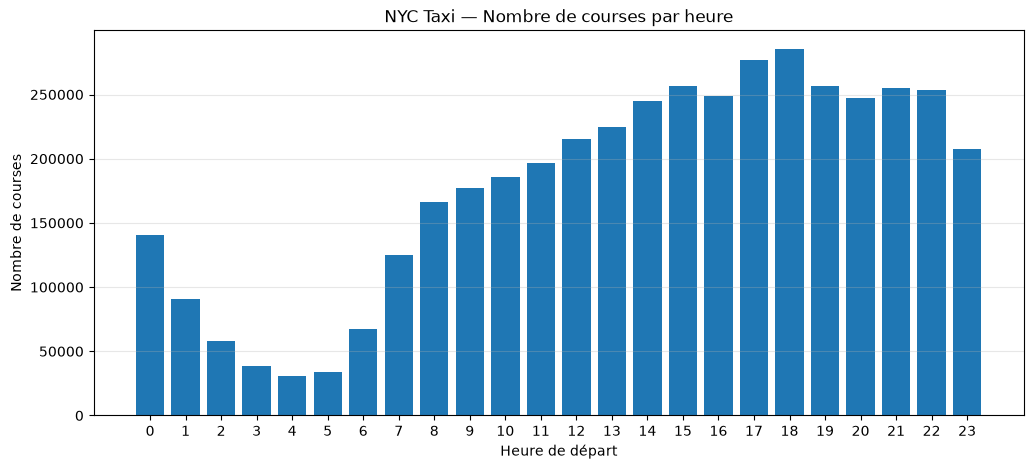

In [73]:
import matplotlib.pyplot as plt

pdf_heures = df_heures.toPandas()

plt.figure(figsize=(12, 5))
plt.bar(pdf_heures["pickup_hour"], pdf_heures["nb_courses"])
plt.xticks(range(24))
plt.xlabel("Heure de départ")
plt.ylabel("Nombre de courses")
plt.title("NYC Taxi — Nombre de courses par heure")
plt.grid(axis="y", alpha=0.3)
plt.show()

In [ ]:
### Interprétation métier : 
* nous pourrons déterminer si l'activité se concentre le matin, en fin de journée ou en soirée. 
* Il faudra observer les résultats réels avant de conclure

In [ ]:
## Comparer les jours ouvrés et les week-ends
### Question métier : l'activité et les revenus diffèrent-ils entre la semaine et le week-end ?

In [74]:
df_jours = df_silver.withColumn(
    "type_jour",
    F.when(
        F.col("pickup_day_of_week").isin(1, 7),
        "Week-end"
    ).otherwise("Jour ouvré")
)

In [ ]:
* Attention : cette classification regroupe du lundi au vendredi dans « Jour ouvré », sans exclure les jours fériés.
* Calculons les indicateurs :

In [75]:
df_comparaison = (
    df_jours
    .groupBy("type_jour")
    .agg(
        F.count("*").alias("nb_courses"),
        F.sum("total_amount").alias("revenu_total"),
        F.avg("total_amount").alias("revenu_moyen_course"),
        F.avg("trip_duration_minute").alias("duree_moyenne_min"),
    )
)

display(df_comparaison.toPandas())

,type_jour,nb_courses,revenu_total,revenu_moyen_course,duree_moyenne_min
0,Week-end,1262327,34083036.28000,27.000164205,16.684838
1,Jour ouvré,3022192,86618823.64000,28.660926784,18.449885


In [ ]:
* Pour comparer plus justement les revenus entre les deux catégories, on peut aussi calculer la part de chaque catégorie dans le volume de courses

In [76]:
total_courses = df_silver.count()

display(
    df_comparaison
        .withColumn(
        "part_courses_pct",
        F.round(F.col("nb_courses") / total_courses * 100, 2)
    )
    .toPandas()
)

,type_jour,nb_courses,revenu_total,revenu_moyen_course,duree_moyenne_min,part_courses_pct
0,Week-end,1262327,34083036.28000,27.000164205,16.684838,29.46
1,Jour ouvré,3022192,86618823.64000,28.660926784,18.449885,70.54


## Analyser la saisonnalité mensuelle
### Question métier : comment l'activité évolue-t-elle au fil des mois ?

In [77]:
df_saisonnalite = (
    df_silver
        .groupBy("pickup_year", "pickup_month")
        .agg(
            F.count("*").alias("nb_courses"),
            F.sum("total_amount").alias("revenu_total"),
            F.avg("total_amount").alias("revenu_moyen_course"),
        )
        .orderBy("pickup_year", "pickup_month")
)

display(df_saisonnalite.toPandas())

,pickup_year,pickup_month,nb_courses,revenu_total,revenu_moyen_course
0,2009,1,1,32.73000,32.730000000
1,2025,4,20,483.83000,24.191500000
2,2025,5,4284495,120701283.74000,28.171647706
3,2025,6,3,59.62000,19.873333333


In [88]:
display(
    spark.table("silver.silver_nyc_taxi")
    .select("periode")
    .distinct()
    .orderBy("periode")
)

DataFrame[periode: int]

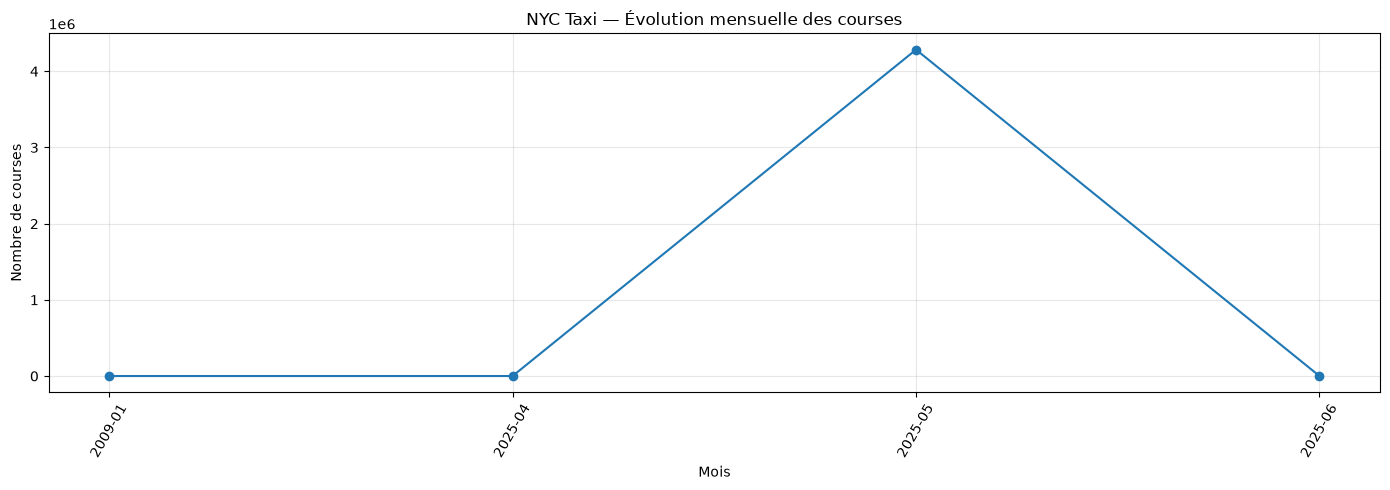

In [89]:
pdf_saison = df_saisonnalite.toPandas()

pdf_saison["periode"] = (
    pdf_saison["pickup_year"].astype(str)
    + "-"
    + pdf_saison["pickup_month"].astype(str).str.zfill(2)
)

plt.figure(figsize=(14, 5))
plt.plot(
    pdf_saison["periode"],
    pdf_saison["nb_courses"],
    marker="o"
)
plt.xlabel("Mois")
plt.ylabel("Nombre de courses")
plt.title("NYC Taxi — Évolution mensuelle des courses")
plt.xticks(rotation=60)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
* Nous pourrons repérer les mois les plus actifs et les périodes de baisse. 
* Cependant, une variation peut aussi venir d'un mois incomplet ou d'un changement dans les données collectées : 
* il faudra vérifier la couverture temporelle avant de conclure à une véritable saisonnalité

## Comparer les années
### Question métier : l'activité progresse-t-elle ou recule-t-elle d'une année à l'autre ?

In [90]:
df_annuel = (
    df_silver
    .groupBy("pickup_year")
    .agg(
        F.count("*").alias("nb_courses"),
        F.sum("total_amount").alias("revenu_total"),
        F.avg("total_amount").alias("revenu_moyen_course"),
    )
    .orderBy("pickup_year")
)

display(df_annuel.toPandas())

,pickup_year,nb_courses,revenu_total,revenu_moyen_course
0,2009,1,32.73000,32.730000000
1,2025,4284518,120701827.19000,28.171623317


In [ ]:
Nous pouvons ensuite calculer les évolutions annuelles avec la fonction analytique lag()

In [91]:
from pyspark.sql.window import Window

fenetre_annees = Window.orderBy("pickup_year")

df_evolution = (
    df_annuel
    .withColumn(
        "courses_annee_precedente",
        F.lag("nb_courses").over(fenetre_annees)
    )
    .withColumn(
        "evolution_courses_pct",
        F.round(
            (
                F.col("nb_courses") / F.col("courses_annee_precedente") - 1) * 100,2
        )
    )
    .withColumn(
        "revenu_annee_precedente", F.lag("revenu_total").over(fenetre_annees)
    )
    .withColumn(
        "evolution_revenu_pct",
        F.round(
            (
                F.col("revenu_total") / F.col("revenu_annee_precedente") - 1) * 100,2
        )
    )
)

display(df_evolution.toPandas())

,pickup_year,nb_courses,revenu_total,revenu_moyen_course,courses_annee_precedente,evolution_courses_pct,revenu_annee_precedente,evolution_revenu_pct
0,2009,1,32.73000,32.730000000,NaN,NaN,None,None
1,2025,4284518,120701827.19000,28.171623317,1.0,428451700.0,32.73000,368780306.94


## afficher les lignes rejetées

In [92]:
from pyspark.sql import functions as F

valid_trip = (
    (F.col("trip_duration_minute") > 0)
    & (F.col("trip_duration_minute") < 1400)
    & (F.col("trip_distance") > 0)
    & (F.col("total_amount") > 0)
)

df_rejected = df_features.filter(~valid_trip)

display(df_rejected.limit(20).toPandas())

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee,trip_duration_minute,trip_date,tip_percent,pickup_hour,pickup_day_of_week,pickup_month,pickup_year
0,7,2025-05-01 00:22:31,2025-05-01 00:22:31,1,1.09000,1,N,229,43,1,8.60000,0.00,0.5,2.87000,0.0,1.0,17.22000,2.5,0.0,0.75,0.000,20250501,33.37,0,5,5,2025
1,7,2025-05-01 00:01:22,2025-05-01 00:01:22,1,5.01000,1,N,148,142,1,19.80000,0.00,0.5,6.39000,0.0,1.0,31.94000,2.5,0.0,0.75,0.000,20250501,32.27,0,5,5,2025
2,7,2025-05-01 00:43:04,2025-05-01 00:43:04,1,5.72000,1,N,230,52,1,22.60000,0.00,0.5,5.67000,0.0,1.0,34.02000,2.5,0.0,0.75,0.000,20250501,25.09,0,5,5,2025
3,2,2025-05-01 00:08:46,2025-05-01 00:18:08,1,2.18000,1,N,230,239,4,-12.10000,-1.00,-0.5,0.00000,0.0,-1.0,-17.85000,-2.5,0.0,-0.75,9.367,20250501,None,0,5,5,2025
4,2,2025-05-01 00:26:39,2025-05-01 00:41:22,1,3.72000,1,N,234,75,2,-17.70000,-1.00,-0.5,0.00000,0.0,-1.0,-23.45000,-2.5,0.0,-0.75,14.717,20250501,None,0,5,5,2025
5,7,2025-05-01 00:16:34,2025-05-01 00:16:34,1,7.20000,1,N,113,24,1,35.90000,0.00,0.5,14.00000,0.0,1.0,55.65000,2.5,0.0,0.75,0.000,20250501,39.00,0,5,5,2025
6,1,2025-05-01 00:28:46,2025-05-01 01:02:22,1,0.00000,99,N,68,188,1,31.50000,0.00,0.5,0.00000,0.0,1.0,33.00000,0.0,0.0,0.00,33.600,20250501,0.00,0,5,5,2025
7,1,2025-05-01 00:12:41,2025-05-01 00:18:05,1,0.00000,1,N,87,231,1,6.50000,4.25,0.5,1.00000,0.0,1.0,13.25000,2.5,0.0,0.75,5.400,20250501,15.38,0,5,5,2025
8,1,2025-05-01 00:12:09,2025-05-01 00:21:09,1,0.00000,1,N,74,168,1,17.50000,0.00,0.5,0.00000,0.0,1.0,19.00000,0.0,0.0,0.00,9.000,20250501,0.00,0,5,5,2025
9,7,2025-05-01 00:08:45,2025-05-01 00:08:45,1,0.88000,1,N,246,50,1,5.80000,0.00,0.5,2.31000,0.0,1.0,13.86000,2.5,0.0,0.75,0.000,20250501,39.83,0,5,5,2025


## Identifier la raison du rejet

In [93]:
df_rejected_detail = (
    df_features
    .withColumn(
        "rejection_reason",
        F.concat_ws(
            ", ",
            F.when(
                F.col("trip_duration_minute").isNull(),
                F.lit("Durée NULL")
            ),
            F.when(
                F.col("trip_duration_minute") <= 0,
                F.lit("Durée <= 0")
            ),
            F.when(
                F.col("trip_duration_minute") >= 1400,
                F.lit("Durée >= 1400 min")
            ),
            F.when(
                F.col("trip_distance").isNull(),
                F.lit("Distance NULL")
            ),
            F.when(
                F.col("trip_distance") <= 0,
                F.lit("Distance <= 0")
            ),
            F.when(
                F.col("total_amount").isNull(),
                F.lit("Montant total NULL")
            ),
            F.when(
                F.col("total_amount") <= 0,
                F.lit("Montant total <= 0")
            ),
        )
    )
    .filter(~valid_trip)
)

In [94]:
display(df_rejected_detail.select(
    "tpep_pickup_datetime",
    "tpep_dropoff_datetime",
    "trip_duration_minute",
    "trip_distance",
    "total_amount",
    "rejection_reason",
).limit(5).toPandas())

,tpep_pickup_datetime,tpep_dropoff_datetime,trip_duration_minute,trip_distance,total_amount,rejection_reason
0,2025-05-01 00:22:31,2025-05-01 00:22:31,0.000,1.09000,17.22000,Durée <= 0
1,2025-05-01 00:01:22,2025-05-01 00:01:22,0.000,5.01000,31.94000,Durée <= 0
2,2025-05-01 00:43:04,2025-05-01 00:43:04,0.000,5.72000,34.02000,Durée <= 0
3,2025-05-01 00:08:46,2025-05-01 00:18:08,9.367,2.18000,-17.85000,Montant total <= 0
4,2025-05-01 00:26:39,2025-05-01 00:41:22,14.717,3.72000,-23.45000,Montant total <= 0


In [95]:
print(f"Nombre de lignes rejetées : {df_rejected.count():,}")

Nombre de lignes rejetées : 307,326
